In [2]:
from __future__ import annotations

import hashlib
import json
import re
import shutil
import time
from dataclasses import dataclass, field
from enum import Enum
from pathlib import Path
from time import perf_counter

import joblib
import numpy as np
import pandas as pd
from scipy.special import expit
from scipy.stats import beta, t as student_t
from collections import deque
import matplotlib.pyplot as plt
from copy import deepcopy
from time import perf_counter
from joblib import Parallel, delayed, parallel_config
from threadpoolctl import threadpool_limits

from typing import Any, Callable, Dict, List, Optional, Sequence, Tuple

from econml.grf import CausalForest

from sklearn.linear_model import SGDClassifier, SGDRegressor
from sklearn.preprocessing import SplineTransformer

In [3]:
def fit_offline_causal_forest(
    X_train,
    D_train,
    Y_train,
    X_eval,
    n_trees=500,
    min_leaf=10,
    max_features="sqrt",
    seed=123,
    n_jobs=-1,
):
    D_train = np.asarray(D_train).astype(float)

    forest = CausalForest(
        n_estimators=n_trees,
        criterion="het",
        min_samples_leaf=min_leaf,
        min_samples_split=2 * min_leaf,
        max_features=max_features,
        max_samples=0.5,
        honest=True,
        fit_intercept=True,
        inference=False,
        n_jobs=n_jobs,
        random_state=seed,
    )

    forest.fit(
        X_train,
        D_train.reshape(-1, 1),
        Y_train,
    )

    tau_hat = forest.predict(X_eval).ravel()
    return tau_hat

# Online Causal Forest

The Online Causal Forest training algorithm is the following:

1. We receive a new datapoint $W_i = (Y_i, D_i, X_i)$
2. The Forest consumes this point and updates summaries and/or splits leafs

## How Forest looks like
The forest consists of $B$ trees $T_b$. Each datapoint is passed to every tree in a forest. The CATE $\tau(x)$ is an average of computed CATEs of each forest:
$$ \tau(x) = \frac{1}{B}\sum_{b=1}^B \tau_b(x). $$

## How each tree splits

Each tree pushes a new observation down to a leaf according to the splits the tree have already made. Every observation becomes either a part of an estimation stream or a structural stream. If its a part of estimation stream, then this observation is used for computation of ATE, otherwise it is used to determine the next split.

Whenever a new leaf is created, we draw a number $m = max(Poisson(\theta) + 1, max_features)$, and then take random $m$ features ${i}$ at which candidate splits will be considered. Then, we create a grid ${c_j}_{j=1}^J$ of a support of each chosen feature. For each pair (i, c) we keep track of summaries $(n_0, n_1, Y_0, Y_1)$, where $n_d$ is a number of observations in a group $d$ and $Y_d$ is a sum of outcomes in a group $d$. In order to determine a split, we wait until the leaf observes at least $n_{struct}$ structural observations and then we split at the $(i, c)$ which yields the maximum heterogeneity between two groups:
$$ (i, c)^* = \text{argmax}_{s = (i, c)} w_L(s)w_R(s)(\tau_L(s) - \tau_R(s))^2, $$
where $w_L(s) = \frac{n_L(s)}{n(s)}$, $n_L(s)$ is the number of observations in a left child, $n_(s)$ is a total number of observations, and $\tau_L(s)$ is an ATE of the left child.

Each leaf's ATE is computed simply as:
$$ \tau(x) = ATE_{current},   $$
where the ATE is using observations from when the split was being decided (from estimation stream) plus the observations that end up in a leaf.

In [4]:
@dataclass
class DataPoint:
    y: float
    d: int
    x: np.ndarray


@dataclass
class DGPSettings:
    d: int # dimension
    e: Callable # propensity function
    m: Callable # prognostic function
    tau: Callable # CATE
    sigma: float # std dev of error term

# varying CATE from wa
def wa_tau1(x: np.ndarray) -> float:
    def zeta(u: float) -> float:
        return 1 + 1/(1 + np.exp(-20 * (u - 1/3)))

    return zeta(x[0]) * zeta(x[1])

# constant CATE from wa
def wa_tau2(x: np.ndarray) -> float:
    return 0.0

# constant prop form wager, athey
def wa_e1(x: np.ndarray) -> float:
    return 1/2

# varying prop from wager, athey
def wa_e2(x: np.ndarray) -> float:
    return 1/4 * (1 + beta.pdf(x[0], a=2, b=4))

# more chill prog from wa
def wa_m1(x: np.ndarray) -> float:
    return -wa_tau1(x)/2

# varying prog from wa
def wa_m2(x: np.ndarray) -> float:
    return 2 * x[0] - 1


class RandomDataStream:
    def __init__(
            self,
            dgp_settings: DGPSettings,
            seed: int = 123,
    ) -> None:
        self.dgp_settings = dgp_settings
        self.seed = seed
        self.rng = np.random.default_rng(seed=self.seed)

    def generate_new_data(self) -> DataPoint:
        n_features = self.dgp_settings.d
        sigma = self.dgp_settings.sigma

        x = self.rng.uniform(0, 1, size=n_features)
        eps = self.rng.normal(loc=0.0, scale=sigma)

        propensity = self.dgp_settings.e(x)
        prognostic = self.dgp_settings.m(x)
        cate = self.dgp_settings.tau(x)

        d = int(self.rng.binomial(n=1, p=propensity))

        y = prognostic + d * cate + eps

        return DataPoint(y=y, d=d, x=x)


In [5]:
class SplineBasis:
    """
    Fixed additive B-spline basis for X in [0, 1]^p.

    Produces:
        [B_1(X_1), ..., B_p(X_p)]

    No interaction terms are included.
    """

    def __init__(
        self,
        n_features,
        n_knots=8,
        degree=3,
        dtype=np.float32,
    ):
        self.n_features = int(n_features)
        self.n_knots = int(n_knots)
        self.degree = int(degree)
        self.dtype = dtype

        if self.n_features < 1:
            raise ValueError("n_features must be positive.")

        if self.n_knots < 2:
            raise ValueError("n_knots must be at least 2.")

        # Same equally spaced knots on [0, 1] for every covariate.
        one_dimensional_knots = np.linspace(
            0.0,
            1.0,
            self.n_knots,
        )

        # Required shape: (n_knots, n_features).
        knots = np.repeat(
            one_dimensional_knots[:, None],
            self.n_features,
            axis=1,
        )

        self.transformer = SplineTransformer(
            knots=knots,
            degree=self.degree,
            extrapolation="constant",
            include_bias=False,
            sparse_output=True,
        )

        # fit() initializes sklearn's internal spline objects.
        # It does not estimate the knots because they were supplied explicitly.
        initialization_X = np.vstack([
            np.zeros(self.n_features),
            np.ones(self.n_features),
        ])

        self.transformer.fit(initialization_X)

    @property
    def n_features_out(self):
        return self.transformer.n_features_out_

    def transform(self, X):
        X = np.asarray(X)

        if X.ndim == 1:
            X = X.reshape(1, -1)

        if X.ndim != 2:
            raise ValueError("X must be a one- or two-dimensional array.")

        if X.shape[1] != self.n_features:
            raise ValueError(
                f"Expected {self.n_features} covariates, "
                f"but received {X.shape[1]}."
            )

        if not np.all(np.isfinite(X)):
            raise ValueError("X contains NaN or infinite values.")

        if np.any(X < 0.0) or np.any(X > 1.0):
            raise ValueError("All covariates must lie in [0, 1].")

        Z = self.transformer.transform(X)
        return Z.astype(self.dtype, copy=False)

class OnlineSGDRegressor:
    def __init__(
        self,
        prior=0.0,
        alpha=1e-4,
        eta0=0.05,
        power_t=0.25,
        average=20,
        random_state=0,
    ):
        self.prior = float(prior)
        self.initialized = False
        self.n_seen = 0

        self.model = SGDRegressor(
            loss="squared_error",
            penalty="l2",
            alpha=alpha,
            fit_intercept=True,
            learning_rate="invscaling",
            eta0=eta0,
            power_t=power_t,

            # If integer-valued, averaging begins after this many
            # observations have been processed.
            average=average,

            # Preserve stream order inside each batch.
            shuffle=False,
            random_state=random_state,
        )

    def predict(self, Z):
        if not self.initialized:
            return np.full(Z.shape[0], self.prior, dtype=float)

        return self.model.predict(Z)

    def partial_fit(self, Z, y):
        y = np.asarray(y, dtype=np.float32).reshape(-1)

        if y.size == 0:
            return self

        if Z.shape[0] != y.size:
            raise ValueError("Z and y have incompatible lengths.")

        # The first call automatically creates coef_ and intercept_.
        self.model.partial_fit(Z, y)

        self.initialized = True
        self.n_seen += y.size
        return self

In [32]:
class CandidateSummaries:
    __slots__ = {
        'features',
        'thresholds',
        'n_cand',
        'n0',
        'n1',
        'y0',
        'y1',
        'score',
        'candidate_idx',
        'compute_score'
    }

    def __init__(self, features: np.ndarray, thresholds: np.ndarray) -> None:
        self.features = features
        self.thresholds = thresholds
        self.n_cand = len(self.features)

        shape = (self.n_cand, 2)

        self.n0 = np.zeros(shape, dtype=np.int32)
        self.n1 = np.zeros(shape, dtype=np.int32)
        self.y0 = np.zeros(shape, dtype=np.float64)
        self.y1 = np.zeros(shape, dtype=np.float64)
        self.score = np.zeros(shape, dtype=np.float64)

        self.candidate_idx = np.arange(self.n_cand)

        self.compute_score: bool = False

    def update(self, x: np.ndarray, d: int, y: float, score: float = None) -> None:
        sides = (x[self.features] >= self.thresholds).astype(np.int8)
        self.compute_score = score is not None

        if d == 1:
            self.n1[self.candidate_idx, sides] += 1

            if self.compute_score:
                self.score[self.candidate_idx, sides] += score
            else:
                self.y1[self.candidate_idx, sides] += y

        else:
            self.n0[self.candidate_idx, sides] += 1

            if self.compute_score:
                self.score[self.candidate_idx, sides] += score
            else:
                self.y0[self.candidate_idx, sides] += y

    def valid_mask(self, min_arm: int = 1) -> np.ndarray:
        return (
            (self.n0[:, 0] >= min_arm)
            & (self.n1[:, 0] >= min_arm)
            & (self.n0[:, 1] >= min_arm)
            & (self.n1[:, 1] >= min_arm)
        )

    def tau(self) -> np.ndarray:
        tau = np.empty((self.n_cand, 2), dtype=np.float64)

        with np.errstate(divide="ignore", invalid="ignore"):
            if self.compute_score:
                tau[:, 0] = self.score[:, 0] / (self.n0[:, 0] + self.n1[:, 0])
                tau[:, 1] = self.score[:, 1] / (self.n0[:, 1] + self.n1[:, 1])
            else:
                tau[:, 0] = self.y1[:, 0] / self.n1[:, 0] - self.y0[:, 0] / self.n0[:, 0]
                tau[:, 1] = self.y1[:, 1] / self.n1[:, 1] - self.y0[:, 1] / self.n0[:, 1]

        return tau

    def split_scores(self, min_arm: int = 1) -> np.ndarray:
        valid = self.valid_mask(min_arm=min_arm)
        tau = self.tau()

        n_left = self.n0[:, 0] + self.n1[:, 0]
        n_right = self.n0[:, 1] + self.n1[:, 1]
        n_total = n_left + n_right

        with np.errstate(divide="ignore", invalid="ignore"):
            w_left = n_left / n_total
            w_right = n_right / n_total
            score = w_left * w_right * (tau[:, 0] - tau[:, 1]) ** 2

        score[~valid] = -np.inf
        return score

    def best_split_index(self, min_arm: int = 1) -> int | None:
        scores = self.split_scores(min_arm=min_arm)

        if np.all(np.isneginf(scores)):
            return None

        return int(np.argmax(scores))

@dataclass(frozen=True)
class SplitLocation:
    feature: int
    threshold: float

    def is_data_point_to_right(self, x: np.ndarray) -> bool:
        return x[self.feature] >= self.threshold


@dataclass(slots=True)
class OnlineSummaries:
    n_0: int = 0
    n_1: int = 0
    y_0: float = 0.0
    y_1: float = 0.0
    score: float = 0.0
    compute_score: bool = False
    min_arm: int = 1

    def update(self, d: int, y: float, score: float = None) -> None:
        self.compute_score = score is not None

        if d == 1:
            self.n_1 += 1

            if self.compute_score:
                self.score += score
            else:
                self.y_1 += y
        else:
            self.n_0 += 1
            if self.compute_score:
                self.score += score
            else:
                self.y_0 += y

    def is_invalid(self) -> bool:
        if self.compute_score:
            return self.n_0 + self.n_1 < self.min_arm
        else:
            return self.n_0 < self.min_arm or self.n_1 < self.min_arm

    def get_ate(self) -> float:
        if self.is_invalid():
            raise ValueError("Invalid ATE: missing treatment arm.")

        if self.compute_score:
            return self.score / (self.n_0 + self.n_1)
        else:
            return self.y_1 / self.n_1 - self.y_0 / self.n_0


class NuisanceStatus(Enum):
    NO_NUISANCES = 0
    ORACLE_NUISANCES = 1
    ESTIMATE_NUISANCES = 2


class OnlineCausalForest:
    def __init__(
            self,
            n_trees: int,
            theta: float,
            max_feature_split_subset_m: int,
            candidate_grid_size_c: float,
            candidate_grid_size_alpha: float,
            candidate_grid_size_beta: float,
            c_split: float,
            alpha_split: float,
            beta_split: float,
            min_arm: int,
            ghost_branch_size: int,
            ghost_queue_size: int,
            subsample_p: float,
            random_seed: int = 123,
            nuisance_status: int = NuisanceStatus.NO_NUISANCES.value,
            warmup_period: int = 0
    ) -> None:
        self.n_trees: int = n_trees
        self.n_seen: int = 0
        self.n_features: int = 0
        self.trees: List = []
        self.theta: float = theta
        self.max_feature_split_subset_m: int = max_feature_split_subset_m
        self.candidate_grid_size_c: float = candidate_grid_size_c
        self.candidate_grid_size_alpha: float = candidate_grid_size_alpha
        self.candidate_grid_size_beta: float = candidate_grid_size_beta
        self.beta_split: float = beta_split
        self.alpha_split: float = alpha_split
        self.c_split: float = c_split
        self.min_arm: int = min_arm
        self.ghost_branch_size: int = ghost_branch_size
        self.ghost_queue_size: int = ghost_queue_size
        self.subsample_p: float = subsample_p
        self.seed = random_seed
        self.stream: Optional[RandomDataStream] = None

        self.rng = np.random.default_rng(seed=self.seed)
        self.nuisance_status = nuisance_status
        self.warmup_period = warmup_period

        if nuisance_status == NuisanceStatus.ORACLE_NUISANCES.value:
            self.prop: Callable | SGDClassifier  = wa_e2
            self.prog0: Callable | OnlineSGDRegressor = wa_m2
            self.prog1: Callable | OnlineSGDRegressor  = (lambda x: wa_m2(x) + wa_tau2(x))
        elif nuisance_status == NuisanceStatus.ESTIMATE_NUISANCES.value:
            self.basis: SplineBasis = None

            self.prop_initialized: bool = False
            self.prop: Callable | SGDClassifier = SGDClassifier(
                loss="log_loss",
                penalty="l2",
                alpha=1e-4,
                learning_rate="invscaling",
                eta0=0.02,
                power_t=0.25,
                average=self.warmup_period,
                shuffle=False,
                random_state=self.seed,
            )
            self.prog0: Callable | OnlineSGDRegressor = OnlineSGDRegressor(
                prior=0.0,
                alpha=1e-4,
                eta0=0.05,
                power_t=0.25,
                average=self.warmup_period,
                random_state=self.seed,
            )
            self.prog1: Callable | OnlineSGDRegressor = OnlineSGDRegressor(
                prior=0.0,
                alpha=1e-4,
                eta0=0.05,
                power_t=0.25,
                average=self.warmup_period,
                random_state=self.seed,
            )


    def fit(self, stream: RandomDataStream) -> 'OnlineCausalForest':
        self.stream = stream
        self.n_features = self.stream.dgp_settings.d

        if self.nuisance_status == NuisanceStatus.ESTIMATE_NUISANCES.value:
            self.basis = SplineBasis(
                    n_features=self.n_features,
                    n_knots=10,
                    degree=3,
            )

        for b in range(self.n_trees):
            self.trees.append(
                CausalTree(
                    forest=self,
                    random_seed=int(self.rng.integers(0, 2**32 - 1)),
                ).fit(self.stream)
            )

        return self

    def consume(self, x: np.ndarray, y: float, d: int) -> None:
        if self.nuisance_status != NuisanceStatus.NO_NUISANCES.value:
            if self.nuisance_status == NuisanceStatus.ORACLE_NUISANCES.value:
                e = self.prop(x)
                mu0 = self.prog0(x)
                mu1 = self.prog1(x)

                score = mu1 - mu0 + d * (y - mu1) / e - (1 - d) * (y - mu0) / (1 - e)
            elif self.n_seen >= self.warmup_period:
                z = self.basis.transform(x)

                e = float(np.clip(self.prop.predict_proba(z)[0, 1], 0.01, 0.99))
                mu0 = float(self.prog0.predict(z)[0])
                mu1 = float(self.prog1.predict(z)[0])

                score = mu1 - mu0 + d * (y - mu1) / e - (1 - d) * (y - mu0) / (1 - e)
            else:
                z = self.basis.transform(x)
        else:
            score = None

        if self.nuisance_status != NuisanceStatus.ESTIMATE_NUISANCES.value or self.n_seen >= self.warmup_period:
            for tree in self.trees:
                tree.consume(y=y, d=d, x=x, score=score)

        if self.nuisance_status == NuisanceStatus.ESTIMATE_NUISANCES.value:
            d_array = np.asarray([d], dtype=np.int8)
            if not self.prop_initialized:
                self.prop.partial_fit(
                    z,
                    d_array,
                    classes=np.array([0, 1], dtype=np.int8),
                )
                self.prop_initialized = True
            else:
                self.prop.partial_fit(z, d_array)

            if d == 0:
                self.prog0.partial_fit(z, y)
            else:
                self.prog1.partial_fit(z, y)

        self.n_seen += 1

    def predict(self, x: np.ndarray) -> float:
        if self.stream is None:
            raise ValueError('Causal Forest has not been fit')

        num = 0.0
        den = 0.0

        w = 1.0

        for tree in self.trees:
            if not tree.tree_is_ready:
                continue

            try:
                pred = tree.predict(x)
            except ValueError:
                continue

            num += w * pred
            den += w

        if den == 0:
            raise ValueError("No valid tree prediction yet.")
        return num / den


class CausalTree:
    def __init__(
            self,
            forest: OnlineCausalForest,
            random_seed: int = 123,
    ) -> None:
        self.root: TreeNode = None
        self.height: int = 0
        self.num_leaves: int = 0
        self.stream: RandomDataStream = None
        self.forest = forest
        self.seed = random_seed
        self.rng = np.random.default_rng(seed=self.seed)

        self.tree_is_ready: bool = False

    def fit(self, stream: RandomDataStream) -> 'CausalTree':
        self.stream = stream
        self.root = TreeNode(
            tree=self,
            random_seed=int(self.rng.integers(0, 2**32 - 1)),
        ).fit(stream)

        self.height = 1
        self.num_leaves = 1

        return self

    def consume(self, x: np.ndarray, y: float, d: int, score: float = None) -> None:
        if self.root is None:
            raise ValueError('Causal Tree has not been fit')

        self.root.consume(y=y, d=d, x=x, score=score, estimation=False)

    def predict(self, x: np.ndarray) -> float:
        if self.root is None:
            raise ValueError('Causal Tree has not been fit')

        return self.root.predict(x)

    def update_height(self, new_height: int) -> None:
        if new_height > self.height:
            self.height = new_height


class TreeNode:
    __slots__ = {
        'depth',
        'tree',
        'parent',
        'children',
        'is_left_child',
        'random_seed',
        'rng',
        'split',
        'theta',
        'max_feature_split_subset_m',
        'min_arm',
        'candidate_grid_size_c',
        'candidate_grid_size_alpha',
        'candidate_grid_size_beta',
        'c_split',
        'alpha_split',
        'beta_split',
        'ghost_branch_size',
        'ghost_queue_size',
        'ghost_root',
        'n_structure',
        'ghost_branches',
        'ghost_side_promoted',
        'structure_candidates',
        'estimation_summaries',
    }

    def __init__(
            self,
            tree: CausalTree,
            parent: Optional[TreeNode] = None,
            is_left_child: Optional[bool] = None,
            random_seed: int = 123,
    ) -> None:
        if parent is None:
            self.depth = 1
        else:
            self.depth = parent.depth + 1

        self.tree = tree
        self.parent: TreeNode = parent
        self.children: List[TreeNode] = []
        self.is_left_child: bool = is_left_child
        self.random_seed: int = random_seed
        self.rng = np.random.default_rng(self.random_seed)

        self.split: SplitLocation = None

        self.theta: float = tree.forest.theta
        self.max_feature_split_subset_m: int = tree.forest.max_feature_split_subset_m
        self.c_split: float = tree.forest.c_split
        self.alpha_split: float = tree.forest.alpha_split
        self.beta_split: float = tree.forest.beta_split
        self.min_arm: int = tree.forest.min_arm
        self.candidate_grid_size_c: float = tree.forest.candidate_grid_size_c
        self.candidate_grid_size_alpha: float = tree.forest.candidate_grid_size_alpha
        self.candidate_grid_size_beta: float = tree.forest.candidate_grid_size_beta
        self.ghost_branch_size: int = tree.forest.ghost_branch_size
        self.ghost_queue_size: int = min(tree.forest.ghost_queue_size, 2 ** (self.ghost_branch_size - 1))
        self.n_structure: int = 0

        self.ghost_branches: List[deque[TreeNode]] = None

        self.ghost_root: bool = False
        self.ghost_side_promoted: List[bool] = None

        self.structure_candidates: CandidateSummaries = None
        self.estimation_summaries: OnlineSummaries = OnlineSummaries(min_arm=self.min_arm)

    def copy(self, parent=None) -> 'TreeNode':
        if parent is None:
            parent = self.parent

        node_copy = TreeNode(self.tree, parent, self.is_left_child, self.random_seed)
        if len(self.children) > 0:
            node_copy.children = [self.children[0].copy(parent=node_copy), self.children[1].copy(parent=node_copy)]
        else:
            node_copy.children = []
        node_copy.rng = self.rng
        node_copy.split = self.split

        return node_copy

    def convert_to_node(self):
        self.structure_candidates = None
        self.estimation_summaries = None
        self.ghost_branches = None
        self.ghost_side_promoted = None
        self.ghost_root = False
        self.rng = None

    def fit(self, stream: RandomDataStream) -> 'TreeNode':
        m = self.rng.poisson(lam=self.theta) + 1
        m = min(m, self.max_feature_split_subset_m, stream.dgp_settings.d)
        m = max(m, 1)
        features: np.ndarray = self.rng.choice(stream.dgp_settings.d, size=m, replace=False)
        grid = np.linspace(0, 1, int(self.candidate_grid_size_c + self.candidate_grid_size_alpha * self.depth ** self.candidate_grid_size_beta + 2.0))[1:-1]

        candidate_features = np.repeat(features, len(grid))
        candidate_thresholds = np.tile(grid, m)

        self.structure_candidates = CandidateSummaries(candidate_features, candidate_thresholds)
        self.estimation_summaries = OnlineSummaries(min_arm=self.min_arm)

        if self.parent is None:
            self.ghost_branches = [deque([], maxlen=self.ghost_queue_size) for _ in range(2)]
            self.ghost_side_promoted = [False] * 2
            self.ghost_root = True

        return self

    def consume(self, x: np.ndarray, d: int, y: float, estimation: bool, score: float = None) -> None:
        if estimation:
            self.estimation_summaries.update(d=d, y=y, score=score)

        if self.split is not None:
            side = int(self.split.is_data_point_to_right(x))

            if not self.ghost_root or len(self.ghost_branches[side]) == 0:
                self.children[side].consume(x=x, d=d, y=y, score=score, estimation=estimation) # above ghost roots or when side of a ghost root has progressed or in between ghost root and leaf
            else:
                self.estimation_summaries.update(d=d, y=y, score=score)

                for i, subtree in enumerate(self.ghost_branches[side]):
                    subtree.consume(x=x, d=d, y=y, score=score, estimation=True)

                self.children[side].consume(x=x, d=d, y=y, score=score, estimation=False)
        elif not estimation:
            self.n_structure += 1
            self.structure_candidates.update(x=x, d=d, y=y, score=score)
            self.check_for_split()

    def update_ghosts(self, level: int, is_left_child: bool, starting_depth: int) -> None:
        if self.parent is None or starting_depth < self.ghost_branch_size:
            return

        if level < self.ghost_branch_size:
            if self.parent.ghost_root:
                snapshot = self.copy()

                self.parent.ghost_branches[int(self.is_left_child)].append(snapshot)
            else:
                self.parent.update_ghosts(level + 1, self.is_left_child, starting_depth)
        elif self.parent.ghost_root:
            side = int(self.is_left_child)
            ghosts = self.parent.ghost_branches[side]
            self.ghost_branches = [deque([], maxlen=self.ghost_queue_size) for _ in range(2)]

            for i, ghost in enumerate(ghosts):
                for ghost_side in range(2):
                    if len(ghost.children) > 0:
                        promoted = ghost.children[ghost_side]
                        promoted.parent = self
                        self.ghost_branches[ghost_side].append(promoted)

            self.parent.ghost_branches[side].clear()
            self.parent.ghost_side_promoted[side] = True

            if all(self.parent.ghost_side_promoted):
                self.parent.convert_to_node()
                if (not self.tree.tree_is_ready) and self.parent is self.tree.root:
                    self.tree.tree_is_ready = True

            path_side = int(is_left_child)
            snapshot = self.children[path_side].copy()

            self.ghost_side_promoted = [False] * 2
            self.ghost_branches[path_side].append(snapshot)
            self.ghost_root = True

    def check_for_split(self) -> None:
        if self.n_structure >= int(self.c_split + self.alpha_split * self.depth ** self.beta_split):
            self.create_split()

    def create_split(self) -> None:
        k = self.structure_candidates.best_split_index(min_arm=self.min_arm)

        if k is None:
            return

        feature = self.structure_candidates.features[k]
        threshold = self.structure_candidates.thresholds[k]

        self.split = SplitLocation(feature, threshold)

        self.children = [
            TreeNode(
                parent=self,
                tree=self.tree,
                is_left_child=bool(side),
                random_seed=int(self.rng.integers(0, 2**32 - 1)),
            ).fit(self.tree.stream) for side in range(2)
        ]
        self.tree.update_height(self.depth + 1)
        self.update_ghosts(level=1, is_left_child=self.is_left_child, starting_depth=self.depth)
        self.structure_candidates = None
        self.rng = None

        self.tree.num_leaves += 1

    def predict(self, x: np.ndarray, fallback_root: TreeNode = None) -> float:
        if self.split is None:
            node = self

            while True:
                summaries = node.estimation_summaries

                if summaries is not None and not summaries.is_invalid():
                    return summaries.get_ate()

                if node is fallback_root or node.parent is None:
                    raise ValueError("No valid estimate inside this ghost.")

                node = node.parent

        else:
            side = int(self.split.is_data_point_to_right(x))

            if self.ghost_root:
                if len(self.ghost_branches[side]) > 0:
                    return self.ghost_branches[side][0].predict(x, fallback_root=self)

                return self.children[side].predict(x, fallback_root=self)


            return self.children[side].predict(x, fallback_root=fallback_root)



## Flexible Monte Carlo interface

Each estimator is represented by either `OnlineEstimatorSpec` or `OfflineEstimatorSpec`.

- An **online** estimator is constructed once per path and must provide `consume(...)` and `compute_ate(...)`.
- An **offline** estimator is a fit function that receives the training arrays and evaluation points and returns the predicted CATE vector.
- `experiment.run(R, estimators)` ensures that every requested estimator has results for the first `R` shared data seeds. It skips estimator/seed pairs already present on disk.
- The run owns the DGP, shared simulation IDs, and data seeds. Each estimator owns its complete `checkpoints` sequence.
- The result directory groups paths by DGP and data seed—not by estimator schedule. Estimators therefore share simulation IDs even when their checkpoint grids differ.
- Algorithm settings and `checkpoints` jointly define an estimator. Each exact specification has its own result file, so saved coverage may be `R=100` for two estimators and `R=20` for a newly added estimator.

The `version` field is part of an estimator's identity. Increment it when implementation code changes without a corresponding change in `kwargs`.


### Common requests

Add an ablation without recomputing existing estimators:

```python
ONLINE_Q1 = OnlineEstimatorSpec(
    name="online_ghost_q1",
    factory=OnlineCausalForest,
    checkpoints=regular_checkpoints(startup_n=200, batch_size=500, epochs=60),
    kwargs={**ONLINE_KWARGS, "ghost_queue_size": 1},
    version="rf21",
)

results = experiment.run(
    20,
    [ONLINE_GHOST, OFFLINE_ECONML, ONLINE_Q1],
)
```

If the first two estimators already cover at least 20 paths, only `ONLINE_Q1` is computed. Later requesting `R=100` fills its missing 80 paths.

Recompute only the offline estimator on the same data paths:

```python
results = experiment.run(
    200,
    [OFFLINE_ECONML],
    recompute={"offline_econml"},
)
```


In [33]:
MC_STORE_FORMAT_VERSION = 3
MC_MANIFEST_FILENAME = "manifest.joblib"
MC_ESTIMATOR_DIRECTORY = "estimators"
MC_LOSS_DEFINITION = "prediction_minus_true_cate"


@dataclass
class OnlineEstimatorSpec:
    """Description of an online estimator used by the MC runner.

    `checkpoints` is the complete estimator-owned evaluation schedule.
    `factory(**kwargs)` creates the estimator. If `initialize_method` is not
    None, that method is called once with a read-only DGP context. The resulting object
    must implement `consume(x=..., y=..., d=...)` and `compute_ate(x)`.
    """

    name: str
    factory: Callable
    checkpoints: Sequence[int]
    kwargs: Dict[str, Any] = field(default_factory=dict)
    version: str = "1"
    seed_kwarg: Optional[str] = "random_seed"
    initialize_method: Optional[str] = "fit"
    kind: str = field(init=False, default="online")

    def __post_init__(self) -> None:
        self.kwargs = deepcopy(dict(self.kwargs))
        _validate_estimator_name(self.name)
        if not callable(self.factory):
            raise TypeError("OnlineEstimatorSpec.factory must be callable.")
        self.checkpoints = _normalize_checkpoints(self.checkpoints)


@dataclass
class OfflineEstimatorSpec:
    """Description of an offline estimator used by the MC runner.

    `checkpoints` is the complete estimator-owned refitting schedule. `fit`
    must return a one-dimensional vector of CATE predictions and accept
    X_train, D_train, Y_train, and X_eval as keyword arguments.
    """

    name: str
    fit: Callable
    checkpoints: Sequence[int]
    kwargs: Dict[str, Any] = field(default_factory=dict)
    version: str = "1"
    seed_kwarg: Optional[str] = "seed"
    n_jobs_kwarg: Optional[str] = "n_jobs"
    kind: str = field(init=False, default="offline")

    def __post_init__(self) -> None:
        self.kwargs = deepcopy(dict(self.kwargs))
        _validate_estimator_name(self.name)
        if not callable(self.fit):
            raise TypeError("OfflineEstimatorSpec.fit must be callable.")
        self.checkpoints = _normalize_checkpoints(self.checkpoints)


EstimatorSpec = OnlineEstimatorSpec | OfflineEstimatorSpec


@dataclass(frozen=True)
class OnlineEstimatorContext:
    """Read-only initialization context; it cannot generate or consume run data."""

    dgp_settings: DGPSettings


def _validate_estimator_name(name: str) -> None:
    if not isinstance(name, str) or not name.strip():
        raise ValueError("Every estimator needs a nonempty string name.")


def _normalize_checkpoints(checkpoints: Sequence[int]) -> Tuple[int, ...]:
    values = tuple(int(checkpoint) for checkpoint in checkpoints)
    if not values or values[0] < 1:
        raise ValueError("Estimator checkpoints must be a nonempty sequence of positive integers.")
    if any(right <= left for left, right in zip(values, values[1:])):
        raise ValueError("Estimator checkpoints must be strictly increasing.")
    return values


def regular_checkpoints(
    *,
    startup_n: int,
    batch_size: int,
    epochs: int,
) -> Tuple[int, ...]:
    """Convenience constructor for a regular estimator-owned checkpoint grid."""
    startup_n = int(startup_n)
    batch_size = int(batch_size)
    epochs = int(epochs)
    if startup_n < 0 or batch_size < 1 or epochs < 1:
        raise ValueError("startup_n cannot be negative; batch_size and epochs must be positive.")
    return tuple(
        map(int, startup_n + batch_size * np.arange(1, epochs + 1))
    )


def _validate_estimators(estimators: Sequence[EstimatorSpec]) -> List[EstimatorSpec]:
    estimators = list(estimators)
    if not estimators:
        raise ValueError("Pass at least one estimator.")
    if not all(isinstance(estimator, (OnlineEstimatorSpec, OfflineEstimatorSpec)) for estimator in estimators):
        raise TypeError("Estimators must be OnlineEstimatorSpec or OfflineEstimatorSpec objects.")

    names = [estimator.name for estimator in estimators]
    if len(set(names)) != len(names):
        raise ValueError("Estimator names must be unique within one run request.")
    for estimator in estimators:
        _metadata_signature(_estimator_metadata(estimator))
    return estimators


def _metadata_signature(metadata: Dict) -> str:
    try:
        return json.dumps(metadata, sort_keys=True, separators=(",", ":"))
    except TypeError as exc:
        raise TypeError(
            "MC metadata and estimator kwargs must contain only JSON-serializable values."
        ) from exc


def _hash_metadata(metadata: Dict) -> str:
    return hashlib.sha256(_metadata_signature(metadata).encode("utf-8")).hexdigest()


def _array_fingerprint(*arrays: np.ndarray) -> str:
    digest = hashlib.sha256()
    for value in arrays:
        array = np.ascontiguousarray(value)
        digest.update(repr(array.shape).encode("utf-8"))
        digest.update(array.dtype.str.encode("utf-8"))
        digest.update(array.view(np.uint8))
    return digest.hexdigest()


def _callable_name(function: Callable) -> str:
    # Keep the v1 naming rule so existing result metadata migrates exactly.
    return getattr(function, "__name__", function.__class__.__name__)


def _estimator_metadata(estimator: EstimatorSpec) -> Dict:
    common = {
        "name": estimator.name,
        "kind": estimator.kind,
        "version": str(estimator.version),
        "kwargs": deepcopy(estimator.kwargs),
        "seed_kwarg": estimator.seed_kwarg,
        "checkpoints": list(map(int, estimator.checkpoints)),
    }
    if isinstance(estimator, OnlineEstimatorSpec):
        common.update(
            implementation=_callable_name(estimator.factory),
            initialize_method=estimator.initialize_method,
        )
    else:
        common.update(
            implementation=_callable_name(estimator.fit),
            n_jobs_kwarg=estimator.n_jobs_kwarg,
        )
    return common


def estimator_signature(estimator: EstimatorSpec) -> str:
    """Identity of algorithm, tuning settings, and estimator-owned checkpoints."""
    return _hash_metadata(_estimator_metadata(estimator))


def _run_metadata_block(metadata: Dict) -> Dict:
    # `simulation` is accepted only to migrate the notebook's v1 result format.
    return metadata["run"] if "run" in metadata else metadata["simulation"]


def _collection_metadata(metadata: Dict) -> Dict:
    """Identity of generated paths: DGP and the shared data-seed rule only."""
    run_metadata = _run_metadata_block(metadata)
    return {
        "dgp": deepcopy(metadata["dgp"]),
        "seed_policy": {
            "base_seed": int(run_metadata["base_seed"]),
        },
    }


def _collection_signature(metadata: Dict) -> str:
    return _hash_metadata(_collection_metadata(metadata))


def _evaluation_metadata(metadata: Dict) -> Dict:
    run_metadata = _run_metadata_block(metadata)
    return {
        "evaluation_seed": int(run_metadata["evaluation_seed"]),
        "evaluation_size": int(run_metadata["evaluation_size"]),
        "evaluation_fingerprint": run_metadata["evaluation_fingerprint"],
    }


def _result_metadata(estimator: EstimatorSpec, evaluation: Dict) -> Dict:
    return {
        "estimator": _estimator_metadata(estimator),
        "evaluation": deepcopy(evaluation),
    }


def result_signature(estimator: EstimatorSpec, evaluation: Dict) -> str:
    """Exact saved-result identity, including the common CATE evaluation sample."""
    return _hash_metadata(_result_metadata(estimator, evaluation))


def make_mc_run_metadata(
    *,
    experiment_name: str,
    dgp_name: str,
    dgp_settings: DGPSettings,
    dgp_parameters: Optional[Dict],
    X_eval: np.ndarray,
    true_cate: np.ndarray,
    evaluation_seed: int,
    base_seed: int,
) -> Dict:
    """Run-owned metadata: DGP, data-seed policy, and common evaluation sample."""
    X_eval = np.asarray(X_eval)
    true_cate = np.asarray(true_cate)
    if X_eval.ndim != 2 or true_cate.shape != (X_eval.shape[0],):
        raise ValueError("X_eval must be 2D and true_cate must have one value per row.")
    if X_eval.shape[0] < 1:
        raise ValueError("The CATE evaluation sample must be nonempty.")
    if not np.all(np.isfinite(X_eval)) or not np.all(np.isfinite(true_cate)):
        raise ValueError("X_eval and true_cate must contain only finite values.")

    metadata = {
        "experiment_name": experiment_name,
        "dgp": {
            "name": dgp_name,
            "dimension": int(dgp_settings.d),
            "sigma": float(dgp_settings.sigma),
            "propensity_function": _callable_name(dgp_settings.e),
            "prognostic_function": _callable_name(dgp_settings.m),
            "cate_function": _callable_name(dgp_settings.tau),
            "parameters": dict(dgp_parameters or {}),
        },
        "run": {
            "base_seed": int(base_seed),
            "evaluation_seed": int(evaluation_seed),
            "evaluation_size": int(X_eval.shape[0]),
            "evaluation_fingerprint": _array_fingerprint(X_eval, true_cate),
        },
    }
    _metadata_signature(metadata)
    return metadata


def _assert_dgp_settings_match(dgp_settings: DGPSettings, metadata: Dict) -> None:
    saved = metadata["dgp"]
    actual = {
        "dimension": int(dgp_settings.d),
        "sigma": float(dgp_settings.sigma),
        "propensity_function": _callable_name(dgp_settings.e),
        "prognostic_function": _callable_name(dgp_settings.m),
        "cate_function": _callable_name(dgp_settings.tau),
    }
    mismatches = [key for key, value in actual.items() if saved.get(key) != value]
    if mismatches:
        raise ValueError(f"DGP settings do not match metadata fields: {mismatches}")


def _manifest_path(results_dir: str | Path) -> Path:
    return Path(results_dir) / MC_MANIFEST_FILENAME


def _atomic_joblib_dump(value: object, path: str | Path) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = path.with_name(path.name + ".tmp")
    joblib.dump(value, temporary_path, compress=3)
    temporary_path.replace(path)


def _data_seed(base_seed: int, simulation_id: int) -> int:
    seed = int(base_seed) + int(simulation_id)
    if seed < 0 or seed > np.iinfo(np.uint32).max:
        raise ValueError("A requested data seed falls outside the uint32 range.")
    return seed


def _estimator_seed(base_seed: int, simulation_id: int, signature: str) -> int:
    payload = f"{int(base_seed)}:{int(simulation_id)}:{signature}".encode("utf-8")
    return int.from_bytes(hashlib.sha256(payload).digest()[:4], "little")


def _make_manifest(metadata: Dict, R: int) -> Dict:
    simulation_ids = np.arange(R, dtype=np.int64)
    base_seed = int(_run_metadata_block(metadata)["base_seed"])
    data_seeds = np.asarray(
        [_data_seed(base_seed, simulation_id) for simulation_id in simulation_ids],
        dtype=np.uint32,
    )
    manifest = {
        "format_version": MC_STORE_FORMAT_VERSION,
        "collection_signature": _collection_signature(metadata),
        "collection_metadata": _collection_metadata(metadata),
        "simulation_ids": simulation_ids,
        "data_seeds": data_seeds,
        "n_data_paths": int(R),
    }
    _validate_manifest(manifest)
    return manifest


def _validate_manifest(manifest: Dict) -> None:
    if not isinstance(manifest, dict) or manifest.get("format_version") != MC_STORE_FORMAT_VERSION:
        raise ValueError("This is not a supported MC result-directory manifest.")
    if manifest.get("collection_signature") != _hash_metadata(manifest["collection_metadata"]):
        raise ValueError("The saved DGP collection signature is inconsistent.")

    simulation_ids = np.asarray(manifest["simulation_ids"])
    data_seeds = np.asarray(manifest["data_seeds"])
    expected_ids = np.arange(simulation_ids.size, dtype=np.int64)
    if not np.array_equal(simulation_ids, expected_ids):
        raise ValueError("Manifest simulation IDs must be consecutive from zero.")
    if data_seeds.shape != simulation_ids.shape or np.unique(data_seeds).size != data_seeds.size:
        raise ValueError("Manifest data seeds must be aligned and unique.")
    if int(manifest["n_data_paths"]) != simulation_ids.size:
        raise ValueError("Manifest n_data_paths is inconsistent.")


def _load_manifest(results_dir: str | Path) -> Dict:
    manifest = joblib.load(_manifest_path(results_dir))
    _validate_manifest(manifest)
    return manifest


def _ensure_manifest(results_dir: str | Path, metadata: Dict, R: int) -> Dict:
    if R < 1:
        raise ValueError("R must be positive.")
    path = _manifest_path(results_dir)
    requested_signature = _collection_signature(metadata)

    if path.exists():
        manifest = _load_manifest(results_dir)
        if manifest["collection_signature"] != requested_signature:
            raise ValueError(
                "This result directory belongs to a different DGP or data-seed policy. "
                "Estimator startup sizes and checkpoint grids may differ, but the DGP must match."
            )
    else:
        manifest = _make_manifest(metadata, 0)

    current_R = int(manifest["n_data_paths"])
    if R > current_R:
        base_seed = int(manifest["collection_metadata"]["seed_policy"]["base_seed"])
        new_ids = np.arange(current_R, R, dtype=np.int64)
        new_data_seeds = np.asarray(
            [_data_seed(base_seed, simulation_id) for simulation_id in new_ids],
            dtype=np.uint32,
        )
        manifest["simulation_ids"] = np.concatenate([manifest["simulation_ids"], new_ids])
        manifest["data_seeds"] = np.concatenate([manifest["data_seeds"], new_data_seeds])
        manifest["n_data_paths"] = int(R)
        _validate_manifest(manifest)

    if not path.exists() or R > current_R:
        _atomic_joblib_dump(manifest, path)
    return manifest


def _safe_estimator_name(name: str) -> str:
    cleaned = re.sub(r"[^A-Za-z0-9_.-]+", "_", name).strip("._")
    return cleaned[:80] or "estimator"


def _estimator_result_path(
    results_dir: str | Path,
    estimator: EstimatorSpec,
    evaluation: Dict,
) -> Path:
    signature = result_signature(estimator, evaluation)
    filename = f"{_safe_estimator_name(estimator.name)}__{signature[:16]}.joblib"
    return Path(results_dir) / MC_ESTIMATOR_DIRECTORY / filename


def _empty_estimator_record(
    collection_signature: str,
    estimator: EstimatorSpec,
    evaluation: Dict,
) -> Dict:
    estimator_metadata = _estimator_metadata(estimator)
    exact_result_signature = result_signature(estimator, evaluation)
    n_checkpoints = len(estimator.checkpoints)
    n_evaluation_points = int(evaluation["evaluation_size"])
    record = {
        "format_version": MC_STORE_FORMAT_VERSION,
        "collection_signature": collection_signature,
        "result_signature": exact_result_signature,
        "estimator_signature": _hash_metadata(estimator_metadata),
        "estimator_seed_signature": _hash_metadata(estimator_metadata),
        "estimator": estimator_metadata,
        "evaluation": deepcopy(evaluation),
        "simulation_ids": np.empty(0, dtype=np.int64),
        "data_seeds": np.empty(0, dtype=np.uint32),
        "estimator_seeds": np.empty(0, dtype=np.uint32),
        "loss_definition": MC_LOSS_DEFINITION,
        "losses": np.empty(
            (n_checkpoints, 0, n_evaluation_points), dtype=np.float64
        ),
        "n_simulations": 0,
    }
    _validate_estimator_record(record)
    return record


def _record_estimator_seed_signature(record: Dict) -> str:
    """Seed identity retained when a behavior-preserving estimator patch is adopted."""
    return record.get("estimator_seed_signature", record["estimator_signature"])


def _validate_estimator_record(record: Dict) -> None:
    if not isinstance(record, dict) or record.get("format_version") != MC_STORE_FORMAT_VERSION:
        raise ValueError("This is not a supported estimator-results file.")
    if record.get("estimator_signature") != _hash_metadata(record["estimator"]):
        raise ValueError("Saved estimator metadata does not match its signature.")
    seed_signature = _record_estimator_seed_signature(record)
    if not isinstance(seed_signature, str) or re.fullmatch(r"[0-9a-f]{64}", seed_signature) is None:
        raise ValueError("Saved estimator seed signature is invalid.")
    exact_metadata = {
        "estimator": record["estimator"],
        "evaluation": record["evaluation"],
    }
    if record.get("result_signature") != _hash_metadata(exact_metadata):
        raise ValueError("Saved estimator evaluation metadata does not match its result signature.")
    if record.get("loss_definition") != MC_LOSS_DEFINITION:
        raise ValueError("Saved losses use an unsupported definition.")

    simulation_ids = np.asarray(record["simulation_ids"])
    n_simulations = simulation_ids.size
    if simulation_ids.ndim != 1 or np.unique(simulation_ids).size != n_simulations:
        raise ValueError("Estimator simulation IDs must be one-dimensional and unique.")
    if n_simulations > 1 and np.any(np.diff(simulation_ids) <= 0):
        raise ValueError("Estimator simulation IDs must be stored in increasing order.")
    if int(record["n_simulations"]) != n_simulations:
        raise ValueError("Estimator n_simulations is inconsistent.")
    for seed_key in ("data_seeds", "estimator_seeds"):
        if np.asarray(record[seed_key]).shape != (n_simulations,):
            raise ValueError(f"{seed_key} does not align with estimator simulation IDs.")

    n_checkpoints = len(record["estimator"]["checkpoints"])
    n_evaluation_points = int(record["evaluation"]["evaluation_size"])
    losses = np.asarray(record["losses"])
    expected_shape = (n_checkpoints, n_simulations, n_evaluation_points)
    if losses.shape != expected_shape:
        raise ValueError(
            f"Saved losses have shape {losses.shape}; expected {expected_shape}."
        )
    if not np.issubdtype(losses.dtype, np.number) or not np.all(np.isfinite(losses)):
        raise ValueError("Saved losses must be finite numeric values.")


def _load_estimator_record(
    results_dir: str | Path,
    estimator: EstimatorSpec,
    evaluation: Dict,
    collection_signature: str,
) -> Dict:
    path = _estimator_result_path(results_dir, estimator, evaluation)
    if not path.exists():
        return _empty_estimator_record(collection_signature, estimator, evaluation)
    record = joblib.load(path)
    _validate_estimator_record(record)
    if record["collection_signature"] != collection_signature:
        raise ValueError(f"Saved results for {estimator.name!r} belong to another DGP.")
    if record["estimator_signature"] != estimator_signature(estimator):
        raise ValueError(f"Saved results for {estimator.name!r} have incompatible settings.")
    if record["result_signature"] != result_signature(estimator, evaluation):
        raise ValueError(f"Saved results for {estimator.name!r} use another evaluation sample.")
    return record


def _adopt_previous_estimator_record(
    results_dir: str | Path,
    estimator: EstimatorSpec,
    evaluation: Dict,
    collection_signature: str,
    base_seed: int,
) -> bool:
    """Adopt one same-name record after an explicitly approved behavior-preserving patch."""
    target_path = _estimator_result_path(results_dir, estimator, evaluation)
    if target_path.exists():
        return False

    estimator_dir = Path(results_dir) / MC_ESTIMATOR_DIRECTORY
    if not estimator_dir.exists():
        return False

    requested_metadata = _estimator_metadata(estimator)
    requested_evaluation_signature = _hash_metadata(evaluation)
    candidates = []
    filename_pattern = f"{_safe_estimator_name(estimator.name)}__*.joblib"
    for source_path in sorted(estimator_dir.glob(filename_pattern)):
        source_record = joblib.load(source_path)
        _validate_estimator_record(source_record)
        saved_metadata = source_record["estimator"]
        compatible = (
            source_record["collection_signature"] == collection_signature
            and _hash_metadata(source_record["evaluation"]) == requested_evaluation_signature
            and saved_metadata.get("name") == estimator.name
            and saved_metadata.get("kind") == estimator.kind
            and saved_metadata.get("checkpoints") == requested_metadata["checkpoints"]
        )
        if compatible:
            candidates.append((source_path, source_record))

    if not candidates:
        return False

    # If earlier adoptions formed one lineage, continue from its newest tip.
    ancestor_signatures = {
        record.get("continued_from_result_signature")
        for _, record in candidates
        if record.get("continued_from_result_signature") is not None
    }
    lineage_tips = [
        candidate
        for candidate in candidates
        if candidate[1]["result_signature"] not in ancestor_signatures
    ]
    if lineage_tips:
        candidates = lineage_tips
    if len(candidates) > 1:
        candidate_labels = [
            (
                f"version={record['estimator']['version']!r}, "
                f"R={record['n_simulations']}, signature={record['result_signature'][:12]}"
            )
            for _, record in candidates
        ]
        raise ValueError(
            f"ignore_new_estimator found multiple compatible saved records for "
            f"{estimator.name!r}: {'; '.join(candidate_labels)}. Keep only one candidate "
            "or give the patched estimator a unique name."
        )

    source_path, source_record = candidates[0]
    seed_signature = _record_estimator_seed_signature(source_record)
    expected_seeds = np.asarray(
        [
            _estimator_seed(base_seed, int(simulation_id), seed_signature)
            for simulation_id in source_record["simulation_ids"]
        ],
        dtype=np.uint32,
    )
    if not np.array_equal(expected_seeds, source_record["estimator_seeds"]):
        raise ValueError(
            f"Cannot safely adopt saved results for {estimator.name!r}: their estimator "
            "seeds do not follow the stored deterministic seed identity."
        )

    adopted_record = deepcopy(source_record)
    adopted_record["continued_from_result_signature"] = source_record["result_signature"]
    adopted_record["estimator"] = requested_metadata
    adopted_record["estimator_signature"] = estimator_signature(estimator)
    adopted_record["estimator_seed_signature"] = seed_signature
    adopted_record["result_signature"] = result_signature(estimator, evaluation)
    _validate_estimator_record(adopted_record)
    _atomic_joblib_dump(adopted_record, target_path)
    print(
        f"{estimator.name}: adopted {adopted_record['n_simulations']} saved paths "
        f"from version {source_record['estimator']['version']!r} for the current estimator; "
        f"the source file {source_path.name!r} was retained."
    )
    return True


def _upsert_estimator_result(
    results_dir: str | Path,
    estimator: EstimatorSpec,
    evaluation: Dict,
    collection_signature: str,
    result: Dict,
    *,
    replace: bool,
) -> Dict:
    n_checkpoints = len(estimator.checkpoints)
    n_evaluation_points = int(evaluation["evaluation_size"])
    expected_result_signature = result_signature(estimator, evaluation)
    if result.get("result_signature") != expected_result_signature:
        raise ValueError("Worker result does not match the requested estimator and evaluation sample.")

    simulation_id = int(result["simulation_id"])
    if simulation_id < 0:
        raise ValueError("simulation_id must be nonnegative.")
    data_seed = int(result["data_seed"])
    estimator_seed = int(result["estimator_seed"])
    max_seed = int(np.iinfo(np.uint32).max)
    if not (0 <= data_seed <= max_seed and 0 <= estimator_seed <= max_seed):
        raise ValueError("Worker seeds must lie in the uint32 range.")

    manifest = _load_manifest(results_dir)
    if manifest["collection_signature"] != collection_signature:
        raise ValueError("Worker result targets a different DGP collection.")
    if simulation_id >= int(manifest["n_data_paths"]):
        raise ValueError("Worker simulation_id is absent from the collection manifest.")
    if data_seed != int(manifest["data_seeds"][simulation_id]):
        raise ValueError("Worker data seed does not match the collection manifest.")
    base_seed = int(manifest["collection_metadata"]["seed_policy"]["base_seed"])
    record = _load_estimator_record(results_dir, estimator, evaluation, collection_signature)
    seed_signature = _record_estimator_seed_signature(record)
    expected_estimator_seed = _estimator_seed(
        base_seed, simulation_id, seed_signature
    )
    if estimator_seed != expected_estimator_seed:
        raise ValueError("Worker estimator seed does not match the deterministic seed rule.")

    values = np.asarray(result["losses"], dtype=np.float64)
    expected_shape = (n_checkpoints, n_evaluation_points)
    if values.shape != expected_shape:
        raise ValueError(
            f"Worker losses have shape {values.shape}; expected {expected_shape}."
        )
    if not np.all(np.isfinite(values)):
        raise ValueError("Worker losses must be finite.")

    positions = np.flatnonzero(record["simulation_ids"] == simulation_id)

    if positions.size:
        if not replace:
            raise ValueError(
                f"Result for estimator {estimator.name!r}, simulation {simulation_id} already exists."
            )
        position = int(positions[0])
        record["data_seeds"][position] = np.uint32(data_seed)
        record["estimator_seeds"][position] = np.uint32(estimator_seed)
        record["losses"][:, position, :] = values
    else:
        record["simulation_ids"] = np.append(record["simulation_ids"], simulation_id)
        record["data_seeds"] = np.append(
            record["data_seeds"], np.uint32(data_seed)
        )
        record["estimator_seeds"] = np.append(
            record["estimator_seeds"], np.uint32(estimator_seed)
        )
        record["losses"] = np.concatenate(
            [record["losses"], values[:, np.newaxis, :]], axis=1
        )

    order = np.argsort(record["simulation_ids"])
    record["simulation_ids"] = record["simulation_ids"][order]
    record["data_seeds"] = record["data_seeds"][order]
    record["estimator_seeds"] = record["estimator_seeds"][order]
    record["losses"] = record["losses"][:, order, :]
    record["n_simulations"] = int(record["simulation_ids"].size)
    _validate_estimator_record(record)
    _atomic_joblib_dump(record, _estimator_result_path(results_dir, estimator, evaluation))
    return record


def _compute_losses(prediction: np.ndarray, true_cate: np.ndarray) -> np.ndarray:
    """Return signed pointwise errors so bias, MSE, and MAE remain recoverable."""
    prediction = np.asarray(prediction, dtype=np.float64).reshape(-1)
    true_cate = np.asarray(true_cate, dtype=np.float64).reshape(-1)
    if prediction.shape != true_cate.shape:
        raise ValueError(
            f"Estimator returned {prediction.size} predictions for {true_cate.size} evaluation points."
        )
    if not np.all(np.isfinite(prediction)) or not np.all(np.isfinite(true_cate)):
        raise ValueError("Predictions and true CATE values must be finite.")
    return prediction - true_cate


def _loss_array_and_checkpoints(
    losses_or_record: np.ndarray | Dict[str, Any],
    checkpoints: Optional[Sequence[int]],
) -> tuple[np.ndarray, np.ndarray]:
    """Normalize either a raw loss array or one estimator result record."""
    if isinstance(losses_or_record, dict):
        if "losses" not in losses_or_record:
            raise KeyError("The estimator record has no 'losses' field.")
        losses = np.asarray(losses_or_record["losses"], dtype=np.float64)
        saved_checkpoints = losses_or_record.get("checkpoints")
        if saved_checkpoints is None:
            saved_checkpoints = losses_or_record.get("estimator", {}).get("checkpoints")
        if checkpoints is None:
            checkpoints = saved_checkpoints
        elif saved_checkpoints is not None and not np.array_equal(
            np.asarray(checkpoints), np.asarray(saved_checkpoints)
        ):
            raise ValueError("Passed checkpoints do not match the estimator record.")
    else:
        losses = np.asarray(losses_or_record, dtype=np.float64)

    if losses.ndim != 3:
        raise ValueError(
            "losses must have shape (checkpoint, simulation, evaluation_point)."
        )
    n_checkpoints, n_simulations, n_evaluation_points = losses.shape
    if n_checkpoints < 1 or n_evaluation_points < 1:
        raise ValueError("Checkpoint and evaluation-point axes must be nonempty.")
    if n_simulations < 3:
        raise ValueError(
            "At least three simulations are required for leave-one-path-out coverage."
        )
    if not np.all(np.isfinite(losses)):
        raise ValueError("losses must contain only finite values.")

    if checkpoints is None:
        raise ValueError(
            "Pass checkpoints, or pass an estimator record containing 'checkpoints'."
        )
    checkpoints_array = np.asarray(checkpoints, dtype=np.float64)
    if checkpoints_array.shape != (n_checkpoints,):
        raise ValueError(
            f"checkpoints has shape {checkpoints_array.shape}; expected {(n_checkpoints,)}."
        )
    if (
        not np.all(np.isfinite(checkpoints_array))
        or np.any(checkpoints_array <= 0)
        or np.any(np.diff(checkpoints_array) <= 0)
    ):
        raise ValueError("checkpoints must be finite, positive, and strictly increasing.")
    return losses, checkpoints_array


def _fit_decay_exponent(
    checkpoints: np.ndarray,
    values: np.ndarray,
    fit_mask: np.ndarray,
) -> Dict[str, Any]:
    """Fit log(value_N) = intercept - exponent * log(N) by OLS."""
    values = np.asarray(values, dtype=np.float64)
    valid = fit_mask & np.isfinite(values) & (values > 0)
    n_requested = int(np.sum(fit_mask))
    n_valid = int(np.sum(valid))
    result: Dict[str, Any] = {
        "estimate": np.nan,
        "intercept": np.nan,
        "r_squared": np.nan,
        "n_checkpoints": n_requested,
        "n_valid_checkpoints": n_valid,
        "all_requested_values_positive": n_valid == n_requested,
        "checkpoint_mask": valid.copy(),
    }
    # Every metric uses the same requested window. Do not silently shorten a
    # squared-bias regression when the finite-R correction becomes nonpositive.
    if n_requested < 3 or n_valid != n_requested:
        return result

    x = np.log(checkpoints[valid])
    y = np.log(values[valid])
    x_centered = x - np.mean(x)
    slope = float(np.dot(x_centered, y - np.mean(y)) / np.dot(x_centered, x_centered))
    fitted = np.mean(y) + slope * x_centered
    residual_ss = float(np.sum(np.square(y - fitted)))
    total_ss = float(np.sum(np.square(y - np.mean(y))))
    result.update(
        estimate=-slope,
        intercept=float(np.mean(y) - slope * np.mean(x)),
        r_squared=(1.0 - residual_ss / total_ss) if total_ss > 0 else 1.0,
    )
    return result


def _rowwise_decay_exponents(
    checkpoints: np.ndarray,
    curves: np.ndarray,
    fit_mask: np.ndarray,
) -> np.ndarray:
    """Vectorized log-log slopes when positivity can differ across rows."""
    curves = np.asarray(curves, dtype=np.float64)
    selected = curves[:, fit_mask]
    exponents = np.full(curves.shape[0], np.nan, dtype=np.float64)
    if selected.shape[1] < 3:
        return exponents
    usable = np.all(np.isfinite(selected) & (selected > 0), axis=1)
    if not np.any(usable):
        return exponents
    x = np.log(checkpoints[fit_mask])
    x_centered = x - np.mean(x)
    denominator = np.dot(x_centered, x_centered)
    exponents[usable] = -(
        np.log(selected[usable]) @ x_centered
    ) / denominator
    return exponents


def _bootstrap_exponent_draws(
    losses: np.ndarray,
    checkpoints: np.ndarray,
    path_mse: np.ndarray,
    path_mae: np.ndarray,
    fit_mask: np.ndarray,
    n_bootstrap: int,
    rng: np.random.Generator,
) -> Dict[str, np.ndarray]:
    """Resample complete simulation paths and refit all four metric curves."""
    n_checkpoints, n_simulations, n_evaluation_points = losses.shape
    counts = rng.multinomial(
        n_simulations,
        np.full(n_simulations, 1.0 / n_simulations),
        size=n_bootstrap,
    ).astype(np.float64, copy=False)

    mse_curves = counts @ path_mse.T / n_simulations
    mae_curves = counts @ path_mae.T / n_simulations
    squared_bias_curves = np.empty((n_bootstrap, n_checkpoints), dtype=np.float64)
    variance_curves = np.empty_like(squared_bias_curves)

    # The integrated Gram matrix retains the cross-path terms needed for bias.
    # It avoids materializing a (bootstrap, checkpoint, simulation, point) array.
    for checkpoint_index in range(n_checkpoints):
        checkpoint_losses = losses[checkpoint_index]
        gram = checkpoint_losses @ checkpoint_losses.T / n_evaluation_points
        quadratic = np.sum((counts @ gram) * counts, axis=1)
        diagonal_sum = counts @ path_mse[checkpoint_index]
        squared_bias_curves[:, checkpoint_index] = (
            quadratic - diagonal_sum
        ) / (n_simulations * (n_simulations - 1))
        variance_curves[:, checkpoint_index] = (
            mse_curves[:, checkpoint_index]
            - squared_bias_curves[:, checkpoint_index]
        )

    return {
        "mse": _rowwise_decay_exponents(checkpoints, mse_curves, fit_mask),
        "mae": _rowwise_decay_exponents(checkpoints, mae_curves, fit_mask),
        "squared_bias": _rowwise_decay_exponents(
            checkpoints, squared_bias_curves, fit_mask
        ),
        "variance": _rowwise_decay_exponents(checkpoints, variance_curves, fit_mask),
    }


def summarize_losses(
    losses_or_record: np.ndarray | Dict[str, Any],
    checkpoints: Optional[Sequence[int]] = None,
    *,
    coverage_level: float = 0.95,
    coverage_quantiles: Sequence[float] = (0.10, 0.50, 0.90),
    exponent_start: Optional[float] = None,
    exponent_end: Optional[float] = None,
    n_bootstrap: int = 0,
    bootstrap_level: float = 0.95,
    bootstrap_seed: Optional[int] = 12345,
) -> Dict[str, Any]:
    """Summarize signed CATE errors stored as (checkpoint, path, point).

    Parameters
    ----------
    losses_or_record
        Either the raw signed errors ``prediction - true_cate`` with shape
        ``(K, R, J)``, or one estimator record returned by ``load_mc_run``.
    checkpoints
        The K sample sizes. This is inferred when an estimator record is passed.
    coverage_level
        Nominal level for leave-one-path-out oracle t intervals.
    coverage_quantiles
        Quantiles across evaluation points of pointwise coverage.
    exponent_start, exponent_end
        Inclusive checkpoint bounds for the empirical log-log regressions.
    n_bootstrap
        Number of complete-path bootstrap draws for exponent uncertainty.
        Zero skips the bootstrap.
    bootstrap_level
        Percentile confidence level for bootstrapped exponents.
    bootstrap_seed
        Seed for path resampling. Use the same seed for matched estimators to
        obtain paired exponent draws.

    Notes
    -----
    ``squared_bias`` uses the finite-R correction
    ``mean_x(mean_r(error)**2) - variance / R``. Hence, up to floating-point
    rounding, ``mse == squared_bias + variance`` at every checkpoint.

    Coverage is an oracle Monte Carlo diagnostic, not a feasible forest
    interval: for each held-out path, its scale and (when requested) bias are
    estimated from the other R-1 paths at the same evaluation point.
    """
    losses, checkpoints_array = _loss_array_and_checkpoints(
        losses_or_record, checkpoints
    )
    n_checkpoints, n_simulations, n_evaluation_points = losses.shape

    if not 0 < coverage_level < 1:
        raise ValueError("coverage_level must lie strictly between zero and one.")
    quantiles = np.asarray(coverage_quantiles, dtype=np.float64)
    if quantiles.ndim != 1 or np.any((quantiles < 0) | (quantiles > 1)):
        raise ValueError("coverage_quantiles must be a one-dimensional sequence in [0, 1].")
    if not 0 < bootstrap_level < 1:
        raise ValueError("bootstrap_level must lie strictly between zero and one.")
    n_bootstrap = int(n_bootstrap)
    if n_bootstrap < 0:
        raise ValueError("n_bootstrap cannot be negative.")

    path_mse = np.mean(np.square(losses), axis=2)
    path_mae = np.mean(np.abs(losses), axis=2)
    mse = np.mean(path_mse, axis=1)
    mae = np.mean(path_mae, axis=1)

    pointwise_bias = np.mean(losses, axis=1)
    pointwise_variance = np.var(losses, axis=1, ddof=1)
    variance = np.mean(pointwise_variance, axis=1)
    uncorrected_squared_bias = np.mean(np.square(pointwise_bias), axis=1)
    squared_bias = uncorrected_squared_bias - variance / n_simulations

    if not np.allclose(mse, squared_bias + variance, rtol=5e-12, atol=5e-14):
        raise RuntimeError("The finite-R MSE decomposition failed numerically.")

    # Leave one complete path out when estimating the oracle scale and bias.
    total_error = np.sum(losses, axis=1)
    total_squared_error = np.sum(np.square(losses), axis=1)
    variance_only_counts = np.zeros(
        (n_checkpoints, n_evaluation_points), dtype=np.int64
    )
    bias_corrected_counts = np.zeros_like(variance_only_counts)
    variance_only_simultaneous_count = np.zeros(n_checkpoints, dtype=np.int64)
    bias_corrected_simultaneous_count = np.zeros(n_checkpoints, dtype=np.int64)
    variance_only_path_rates = np.empty(
        (n_checkpoints, n_simulations), dtype=np.float64
    )
    bias_corrected_path_rates = np.empty_like(variance_only_path_rates)
    variance_only_interval_length_sum = np.zeros(n_checkpoints, dtype=np.float64)
    bias_corrected_interval_length_sum = np.zeros(n_checkpoints, dtype=np.float64)
    loo_n = n_simulations - 1
    critical_value = float(
        student_t.ppf(0.5 + coverage_level / 2.0, df=n_simulations - 2)
    )

    for simulation_index in range(n_simulations):
        held_out = losses[:, simulation_index, :]
        loo_sum = total_error - held_out
        loo_squared_sum = total_squared_error - np.square(held_out)
        loo_bias = loo_sum / loo_n
        loo_ss = loo_squared_sum - np.square(loo_sum) / loo_n
        # Only roundoff can make this centered sum of squares negative.
        loo_variance = np.maximum(loo_ss, 0.0) / (loo_n - 1)
        variance_only_half_width = critical_value * np.sqrt(loo_variance)
        # The bias estimate is a mean over R-1 independent calibration paths.
        # Its estimation variance adds the usual predictive-t factor.
        bias_corrected_half_width = (
            variance_only_half_width * np.sqrt(1.0 + 1.0 / loo_n)
        )

        variance_only_hit = np.abs(held_out) <= variance_only_half_width
        bias_corrected_hit = np.abs(held_out - loo_bias) <= bias_corrected_half_width
        variance_only_counts += variance_only_hit
        bias_corrected_counts += bias_corrected_hit
        variance_only_simultaneous_count += np.all(variance_only_hit, axis=1)
        bias_corrected_simultaneous_count += np.all(bias_corrected_hit, axis=1)
        variance_only_path_rates[:, simulation_index] = np.mean(
            variance_only_hit, axis=1
        )
        bias_corrected_path_rates[:, simulation_index] = np.mean(
            bias_corrected_hit, axis=1
        )
        variance_only_interval_length_sum += 2.0 * np.sum(
            variance_only_half_width, axis=1
        )
        bias_corrected_interval_length_sum += 2.0 * np.sum(
            bias_corrected_half_width, axis=1
        )

    variance_only_pointwise = variance_only_counts / n_simulations
    bias_corrected_pointwise = bias_corrected_counts / n_simulations
    coverage = {
        "method": "leave_one_path_out_oracle_predictive_t",
        "nominal_level": float(coverage_level),
        "t_degrees_of_freedom": int(n_simulations - 2),
        "critical_value": critical_value,
        "variance_only": np.mean(variance_only_pointwise, axis=1),
        "bias_corrected": np.mean(bias_corrected_pointwise, axis=1),
        "variance_only_by_path": variance_only_path_rates,
        "bias_corrected_by_path": bias_corrected_path_rates,
        "variance_only_mc_standard_error": (
            np.std(variance_only_path_rates, axis=1, ddof=1)
            / np.sqrt(n_simulations)
        ),
        "bias_corrected_mc_standard_error": (
            np.std(bias_corrected_path_rates, axis=1, ddof=1)
            / np.sqrt(n_simulations)
        ),
        "variance_only_by_evaluation_point": variance_only_pointwise,
        "bias_corrected_by_evaluation_point": bias_corrected_pointwise,
        "quantile_levels": quantiles.copy(),
        "variance_only_pointwise_quantiles": np.quantile(
            variance_only_pointwise, quantiles, axis=1
        ).T,
        "bias_corrected_pointwise_quantiles": np.quantile(
            bias_corrected_pointwise, quantiles, axis=1
        ).T,
        "variance_only_simultaneous": (
            variance_only_simultaneous_count / n_simulations
        ),
        "bias_corrected_simultaneous": (
            bias_corrected_simultaneous_count / n_simulations
        ),
        "simultaneous_note": (
            "Fraction of paths covered at every evaluation point by the "
            "unadjusted pointwise intervals; this is not a calibrated uniform band."
        ),
        "variance_only_mean_interval_length": (
            variance_only_interval_length_sum
            / (n_simulations * n_evaluation_points)
        ),
        "bias_corrected_mean_interval_length": (
            bias_corrected_interval_length_sum
            / (n_simulations * n_evaluation_points)
        ),
    }

    fit_mask = np.ones(n_checkpoints, dtype=bool)
    if exponent_start is not None:
        fit_mask &= checkpoints_array >= float(exponent_start)
    if exponent_end is not None:
        fit_mask &= checkpoints_array <= float(exponent_end)
    metric_curves = {
        "mse": mse,
        "mae": mae,
        "squared_bias": squared_bias,
        "variance": variance,
    }
    exponents = {
        name: _fit_decay_exponent(checkpoints_array, curve, fit_mask)
        for name, curve in metric_curves.items()
    }
    exponent_output: Dict[str, Any] = {
        "model": "log(metric_N) = intercept - exponent * log(N)",
        "requested_checkpoint_mask": fit_mask.copy(),
        "start": None if exponent_start is None else float(exponent_start),
        "end": None if exponent_end is None else float(exponent_end),
        "metrics": exponents,
        "bootstrap": None,
    }

    if n_bootstrap:
        rng = np.random.default_rng(bootstrap_seed)
        if np.sum(fit_mask) < 3:
            bootstrap_draws = {
                name: np.full(n_bootstrap, np.nan, dtype=np.float64)
                for name in metric_curves
            }
        else:
            bootstrap_draws = _bootstrap_exponent_draws(
                losses,
                checkpoints_array,
                path_mse,
                path_mae,
                fit_mask,
                n_bootstrap,
                rng,
            )
        lower_probability = (1.0 - bootstrap_level) / 2.0
        upper_probability = 1.0 - lower_probability
        bootstrap_summary: Dict[str, Any] = {
            "method": "complete_path_percentile",
            "level": float(bootstrap_level),
            "n_resamples": n_bootstrap,
            "seed": bootstrap_seed,
            "metrics": {},
        }
        for name, draws in bootstrap_draws.items():
            finite = draws[np.isfinite(draws)]
            if finite.size:
                confidence_interval = np.quantile(
                    finite, [lower_probability, upper_probability]
                )
                standard_error = (
                    float(np.std(finite, ddof=1)) if finite.size > 1 else np.nan
                )
                median = float(np.median(finite))
            else:
                confidence_interval = np.array([np.nan, np.nan])
                standard_error = np.nan
                median = np.nan
            bootstrap_summary["metrics"][name] = {
                "standard_error": standard_error,
                "median": median,
                "confidence_interval": confidence_interval,
                "n_valid": int(finite.size),
                "valid_fraction": float(finite.size / n_bootstrap),
                "draws": draws,
            }
        exponent_output["bootstrap"] = bootstrap_summary

    return {
        "checkpoints": checkpoints_array,
        "n_simulations": n_simulations,
        "n_evaluation_points": n_evaluation_points,
        "mse": mse,
        "mae": mae,
        "squared_bias": squared_bias,
        "squared_bias_uncorrected": uncorrected_squared_bias,
        "variance": variance,
        "path_mse": path_mse,
        "path_mae": path_mae,
        "pointwise_bias": pointwise_bias,
        "pointwise_variance": pointwise_variance,
        "coverage": coverage,
        "exponents": exponent_output,
    }


def _initialize_online_estimator(
    estimator_spec: OnlineEstimatorSpec,
    estimator_seed: int,
    context: OnlineEstimatorContext,
):
    kwargs = deepcopy(estimator_spec.kwargs)
    if estimator_spec.seed_kwarg is not None:
        kwargs[estimator_spec.seed_kwarg] = estimator_seed
    estimator = estimator_spec.factory(**kwargs)

    if estimator_spec.initialize_method is not None:
        initialize = getattr(estimator, estimator_spec.initialize_method, None)
        if not callable(initialize):
            raise TypeError(
                f"Online estimator {estimator_spec.name!r} has no callable "
                f"{estimator_spec.initialize_method!r} initialization method."
            )
        initialized = initialize(context)
        if initialized is not None:
            estimator = initialized

    for method_name in ("consume", "predict"):
        if not callable(getattr(estimator, method_name, None)):
            raise TypeError(
                f"Online estimator {estimator_spec.name!r} must implement {method_name}()."
            )
    return estimator


def _run_online_estimator_path(
    estimator_spec: OnlineEstimatorSpec,
    data_seed: int,
    estimator_seed: int,
    dgp_settings: DGPSettings,
    X_eval: np.ndarray,
    true_cate: np.ndarray,
) -> np.ndarray:
    stream = RandomDataStream(dgp_settings=dgp_settings, seed=data_seed)
    context = OnlineEstimatorContext(dgp_settings=dgp_settings)
    estimator = _initialize_online_estimator(estimator_spec, estimator_seed, context)
    checkpoints = estimator_spec.checkpoints
    losses = np.empty((len(checkpoints), X_eval.shape[0]), dtype=np.float64)
    n_seen = 0

    for checkpoint_index, checkpoint in enumerate(checkpoints):
        while n_seen < checkpoint:
            obs = stream.generate_new_data()
            estimator.consume(x=obs.x, y=obs.y, d=obs.d)
            n_seen += 1
        prediction = np.fromiter(
            (estimator.predict(x) for x in X_eval),
            dtype=np.float64,
            count=X_eval.shape[0],
        )
        losses[checkpoint_index, :] = _compute_losses(prediction, true_cate)
    return losses


def _run_offline_estimator_path(
    estimator_spec: OfflineEstimatorSpec,
    data_seed: int,
    estimator_seed: int,
    dgp_settings: DGPSettings,
    X_eval: np.ndarray,
    true_cate: np.ndarray,
) -> np.ndarray:
    stream = RandomDataStream(dgp_settings=dgp_settings, seed=data_seed)
    checkpoints = estimator_spec.checkpoints
    n_total = checkpoints[-1]
    X_train = np.empty((n_total, dgp_settings.d), dtype=np.float64)
    D_train = np.empty(n_total, dtype=np.int8)
    Y_train = np.empty(n_total, dtype=np.float64)
    losses = np.empty((len(checkpoints), X_eval.shape[0]), dtype=np.float64)

    def add_observation(index: int) -> None:
        obs = stream.generate_new_data()
        X_train[index] = obs.x
        D_train[index] = obs.d
        Y_train[index] = obs.y

    n_seen = 0
    for checkpoint_index, checkpoint in enumerate(checkpoints):
        while n_seen < checkpoint:
            add_observation(n_seen)
            n_seen += 1

        kwargs = deepcopy(estimator_spec.kwargs)
        if estimator_spec.seed_kwarg is not None:
            kwargs[estimator_spec.seed_kwarg] = estimator_seed
        if estimator_spec.n_jobs_kwarg is not None:
            # Parallelism belongs to the outer MC loop.
            kwargs[estimator_spec.n_jobs_kwarg] = 1
        prediction = estimator_spec.fit(
            X_train=X_train[:n_seen],
            D_train=D_train[:n_seen],
            Y_train=Y_train[:n_seen],
            X_eval=X_eval,
            **kwargs,
        )
        if isinstance(prediction, tuple):
            raise TypeError(
                f"Offline estimator {estimator_spec.name!r} returned a tuple. "
                "Its fit function must return only predicted CATE values."
            )
        losses[checkpoint_index, :] = _compute_losses(prediction, true_cate)
    return losses


def _run_estimator_path(
    estimator_spec: EstimatorSpec,
    exact_result_signature: str,
    simulation_id: int,
    data_seed: int,
    estimator_seed: int,
    dgp_settings: DGPSettings,
    X_eval: np.ndarray,
    true_cate: np.ndarray,
) -> Dict:
    with threadpool_limits(limits=1):
        if isinstance(estimator_spec, OnlineEstimatorSpec):
            losses = _run_online_estimator_path(
                estimator_spec,
                data_seed,
                estimator_seed,
                dgp_settings,
                X_eval,
                true_cate,
            )
        else:
            losses = _run_offline_estimator_path(
                estimator_spec,
                data_seed,
                estimator_seed,
                dgp_settings,
                X_eval,
                true_cate,
            )
    return {
        "result_signature": exact_result_signature,
        "simulation_id": int(simulation_id),
        "data_seed": int(data_seed),
        "estimator_seed": int(estimator_seed),
        "losses": losses,
    }


def _normalize_estimator_name_option(
    value: bool | Sequence[str],
    estimators: Sequence[EstimatorSpec],
    option_name: str,
) -> set[str]:
    estimator_names = {estimator.name for estimator in estimators}
    if value is True:
        return estimator_names
    if value is False or value is None:
        return set()
    if isinstance(value, str):
        names = {value}
    else:
        names = set(value)
    unknown = names - estimator_names
    if unknown:
        raise ValueError(
            f"{option_name} names estimators absent from this request: {sorted(unknown)}"
        )
    return names


def _normalize_recompute(
    recompute: bool | Sequence[str], estimators: Sequence[EstimatorSpec]
) -> set[str]:
    return _normalize_estimator_name_option(recompute, estimators, "recompute")


def _normalize_ignore_new_estimator(
    ignore_new_estimator: bool | Sequence[str],
    estimators: Sequence[EstimatorSpec],
) -> set[str]:
    return _normalize_estimator_name_option(
        ignore_new_estimator, estimators, "ignore_new_estimator"
    )


def load_mc_run(
    results_dir: str | Path,
    estimators: Sequence[EstimatorSpec],
    metadata: Dict,
    X_eval: np.ndarray,
    true_cate: np.ndarray,
    *,
    R: Optional[int] = None,
) -> Dict:
    """Load requested estimators matched by data simulation ID, not checkpoint grid."""
    estimators = _validate_estimators(estimators)
    manifest = _load_manifest(results_dir)
    if manifest["collection_signature"] != _collection_signature(metadata):
        raise ValueError("The requested DGP or data-seed policy does not match this collection.")
    evaluation = _evaluation_metadata(metadata)
    if _array_fingerprint(X_eval, true_cate) != evaluation["evaluation_fingerprint"]:
        raise ValueError("X_eval or true_cate does not match the requested evaluation metadata.")
    available_R = int(manifest["n_data_paths"])
    R = available_R if R is None else int(R)
    if R < 1 or R > available_R:
        raise ValueError(f"R must lie in [1, {available_R}] for this saved collection.")

    target_ids = manifest["simulation_ids"][:R]
    target_data_seeds = manifest["data_seeds"][:R]
    result_view = {
        "R": R,
        "metadata": deepcopy(metadata),
        "collection_metadata": deepcopy(manifest["collection_metadata"]),
        "simulation_ids": target_ids.copy(),
        "data_seeds": target_data_seeds.copy(),
        "estimators": {},
    }

    for estimator in estimators:
        record = _load_estimator_record(
            results_dir, estimator, evaluation, manifest["collection_signature"]
        )
        position_by_id = {
            int(simulation_id): position
            for position, simulation_id in enumerate(record["simulation_ids"])
        }
        missing = [int(simulation_id) for simulation_id in target_ids if int(simulation_id) not in position_by_id]
        if missing:
            raise ValueError(
                f"Estimator {estimator.name!r} is missing {len(missing)} of the requested R={R} paths."
            )
        positions = np.asarray([position_by_id[int(simulation_id)] for simulation_id in target_ids])
        if not np.array_equal(record["data_seeds"][positions], target_data_seeds):
            raise ValueError(f"Saved data seeds for estimator {estimator.name!r} do not match the manifest.")
        result_view["estimators"][estimator.name] = {
            "kind": estimator.kind,
            "estimator_signature": estimator_signature(estimator),
            "result_signature": result_signature(estimator, evaluation),
            "evaluation": deepcopy(evaluation),
            "checkpoints": np.asarray(estimator.checkpoints, dtype=np.int64),
            "simulation_ids": target_ids.copy(),
            "data_seeds": target_data_seeds.copy(),
            "estimator_seeds": record["estimator_seeds"][positions].copy(),
            "loss_definition": record["loss_definition"],
            "losses": record["losses"][:, positions, :].copy(),
        }
    return result_view


def get_saved_seeds(
    results_dir: str | Path,
    *,
    R: Optional[int] = None,
    estimator: Optional[EstimatorSpec] = None,
    metadata: Optional[Dict] = None,
    X_eval: Optional[np.ndarray] = None,
    true_cate: Optional[np.ndarray] = None,
) -> Dict[str, List[int]]:
    """Return shared data seeds, plus algorithm seeds for one estimator if requested."""
    manifest = _load_manifest(results_dir)
    available_R = int(manifest["n_data_paths"])
    R = available_R if R is None else int(R)
    if R < 0 or R > available_R:
        raise ValueError(f"R must lie in [0, {available_R}].")
    result = {
        "simulation_ids": manifest["simulation_ids"][:R].astype(int).tolist(),
        "data": manifest["data_seeds"][:R].astype(int).tolist(),
    }
    if estimator is not None:
        if metadata is None or X_eval is None or true_cate is None:
            raise ValueError("Pass metadata, X_eval, and true_cate to retrieve estimator seeds.")
        view = load_mc_run(
            results_dir,
            [estimator],
            metadata,
            X_eval,
            true_cate,
            R=R,
        )
        result["estimator"] = view["estimators"][estimator.name]["estimator_seeds"].astype(int).tolist()
    return result


def list_saved_estimators(results_dir: str | Path) -> pd.DataFrame:
    """Inventory every exact estimator specification already saved on disk."""
    manifest = _load_manifest(results_dir)
    estimator_dir = Path(results_dir) / MC_ESTIMATOR_DIRECTORY
    rows = []
    if estimator_dir.exists():
        for path in sorted(estimator_dir.glob("*.joblib")):
            record = joblib.load(path)
            _validate_estimator_record(record)
            if record["collection_signature"] != manifest["collection_signature"]:
                raise ValueError(f"Estimator file {path} belongs to another DGP collection.")
            rows.append(
                {
                    "name": record["estimator"]["name"],
                    "kind": record["estimator"]["kind"],
                    "version": record["estimator"]["version"],
                    "R_saved": int(record["n_simulations"]),
                    "n_checkpoints": len(record["estimator"]["checkpoints"]),
                    "first_checkpoint": int(record["estimator"]["checkpoints"][0]),
                    "last_checkpoint": int(record["estimator"]["checkpoints"][-1]),
                    "checkpoints": record["estimator"]["checkpoints"],
                    "result_signature": record["result_signature"],
                    "kwargs": record["estimator"]["kwargs"],
                }
            )
    return pd.DataFrame(
        rows,
        columns=[
            "name",
            "kind",
            "version",
            "R_saved",
            "n_checkpoints",
            "first_checkpoint",
            "last_checkpoint",
            "checkpoints",
            "result_signature",
            "kwargs",
        ],
    )


def run_mc(
    results_dir: str | Path,
    R: int,
    estimators: Sequence[EstimatorSpec],
    metadata: Dict,
    dgp_settings: DGPSettings,
    X_eval: np.ndarray,
    true_cate: np.ndarray,
    *,
    n_jobs: int = 28,
    recompute: bool | Sequence[str] = False,
    ignore_new_estimator: bool | Sequence[str] = False,
    verbose: int = 10,
) -> Dict:
    """Ensure each requested estimator has results on the first R shared paths.

    Existing exact estimator/simulation pairs are skipped. Set `recompute=True`
    or pass estimator names to replace only those estimators on the same paths.
    Set `ignore_new_estimator=True`, or pass estimator names, only after a
    behavior-preserving patch: a unique same-name saved record with identical
    kind, checkpoints, DGP, and evaluation sample is adopted under the current
    estimator specification, and only missing paths are computed.
    Every completed estimator path is checkpointed by the parent process.
    """
    estimators = _validate_estimators(estimators)
    R = int(R)
    if n_jobs < 1:
        raise ValueError("n_jobs must be positive.")
    X_eval = np.asarray(X_eval, dtype=np.float64)
    true_cate = np.asarray(true_cate, dtype=np.float64)
    evaluation = _evaluation_metadata(metadata)
    if _array_fingerprint(X_eval, true_cate) != evaluation["evaluation_fingerprint"]:
        raise ValueError("X_eval or true_cate does not match the experiment metadata.")
    _assert_dgp_settings_match(dgp_settings, metadata)

    manifest = _ensure_manifest(results_dir, metadata, int(R))
    target_ids = manifest["simulation_ids"][:R]
    target_data_seeds = manifest["data_seeds"][:R]
    collection_signature = manifest["collection_signature"]
    base_seed = int(manifest["collection_metadata"]["seed_policy"]["base_seed"])
    recompute_names = _normalize_recompute(recompute, estimators)
    ignore_new_estimator_names = _normalize_ignore_new_estimator(
        ignore_new_estimator, estimators
    )
    conflicting_names = recompute_names & ignore_new_estimator_names
    if conflicting_names:
        raise ValueError(
            "The same estimator cannot be both recomputed and adopted via "
            f"ignore_new_estimator: {sorted(conflicting_names)}"
        )

    tasks = []
    request_by_result_signature = {}
    recompute_by_result_signature = {}
    for estimator in estimators:
        exact_result_signature = result_signature(estimator, evaluation)
        request_by_result_signature[exact_result_signature] = estimator
        recompute_this = estimator.name in recompute_names
        recompute_by_result_signature[exact_result_signature] = recompute_this
        if estimator.name in ignore_new_estimator_names:
            _adopt_previous_estimator_record(
                results_dir,
                estimator,
                evaluation,
                collection_signature,
                base_seed,
            )
        record = _load_estimator_record(
            results_dir,
            estimator,
            evaluation,
            collection_signature,
        )
        seed_signature = _record_estimator_seed_signature(record)
        saved_ids = set(map(int, record["simulation_ids"]))
        scheduled_ids = [
            int(simulation_id)
            for simulation_id in target_ids
            if recompute_this or int(simulation_id) not in saved_ids
        ]
        print(
            f"{estimator.name}: {len(saved_ids.intersection(map(int, target_ids)))} / {R} requested paths "
            f"already saved; scheduling {len(scheduled_ids)} "
            f"(n={estimator.checkpoints[0]}..{estimator.checkpoints[-1]})."
        )
        for simulation_id in scheduled_ids:
            data_seed = int(target_data_seeds[simulation_id])
            tasks.append(
                (
                    estimator,
                    exact_result_signature,
                    simulation_id,
                    data_seed,
                    _estimator_seed(base_seed, simulation_id, seed_signature),
                )
            )

    if tasks:
        workers = min(int(n_jobs), len(tasks))
        print(f"Running {len(tasks)} estimator paths on {workers} worker processes.")
        with parallel_config(backend="loky", n_jobs=workers, inner_max_num_threads=1):
            result_iterator = Parallel(
                verbose=verbose,
                batch_size=1,
                pre_dispatch=workers,
                return_as="generator_unordered",
            )(
                delayed(_run_estimator_path)(
                    estimator_spec=estimator,
                    exact_result_signature=exact_result_signature,
                    simulation_id=simulation_id,
                    data_seed=data_seed,
                    estimator_seed=estimator_seed,
                    dgp_settings=dgp_settings,
                    X_eval=X_eval,
                    true_cate=true_cate,
                )
                for estimator, exact_result_signature, simulation_id, data_seed, estimator_seed in tasks
            )
            for result in result_iterator:
                exact_result_signature = result["result_signature"]
                estimator = request_by_result_signature[exact_result_signature]
                _upsert_estimator_result(
                    results_dir,
                    estimator,
                    evaluation,
                    collection_signature,
                    result,
                    replace=recompute_by_result_signature[exact_result_signature],
                )
    else:
        print("All requested estimator paths are already saved; no computation needed.")

    result_view = load_mc_run(
        results_dir,
        estimators,
        metadata,
        X_eval,
        true_cate,
        R=R,
    )
    print(f"Returning a matched R={R} collection for {len(estimators)} estimator(s).")
    return result_view


@dataclass
class MCExperiment:
    """Bound experiment context; a new request then needs only R and estimators."""

    results_dir: str | Path
    metadata: Dict
    dgp_settings: DGPSettings
    X_eval: np.ndarray
    true_cate: np.ndarray
    n_jobs: int = 28
    verbose: int = 10

    def __post_init__(self) -> None:
        self.results_dir = Path(self.results_dir)
        self.metadata = deepcopy(self.metadata)
        self.X_eval = np.asarray(self.X_eval, dtype=np.float64)
        self.true_cate = np.asarray(self.true_cate, dtype=np.float64)
        _assert_dgp_settings_match(self.dgp_settings, self.metadata)
        if _array_fingerprint(self.X_eval, self.true_cate) != _evaluation_metadata(self.metadata)["evaluation_fingerprint"]:
            raise ValueError("MCExperiment evaluation arrays do not match its metadata.")

    def run(
        self,
        R: int,
        estimators: Sequence[EstimatorSpec],
        *,
        recompute: bool | Sequence[str] = False,
        ignore_new_estimator: bool | Sequence[str] = False,
        n_jobs: Optional[int] = None,
        verbose: Optional[int] = None,
    ) -> Dict:
        return run_mc(
            results_dir=self.results_dir,
            R=R,
            estimators=estimators,
            metadata=self.metadata,
            dgp_settings=self.dgp_settings,
            X_eval=self.X_eval,
            true_cate=self.true_cate,
            n_jobs=self.n_jobs if n_jobs is None else n_jobs,
            recompute=recompute,
            ignore_new_estimator=ignore_new_estimator,
            verbose=self.verbose if verbose is None else verbose,
        )

    def load(self, R: int, estimators: Sequence[EstimatorSpec]) -> Dict:
        return load_mc_run(
            self.results_dir,
            estimators,
            self.metadata,
            self.X_eval,
            self.true_cate,
            R=R,
        )

    def seeds(
        self,
        *,
        R: Optional[int] = None,
        estimator: Optional[EstimatorSpec] = None,
    ) -> Dict[str, List[int]]:
        return get_saved_seeds(
            self.results_dir,
            R=R,
            estimator=estimator,
            metadata=self.metadata if estimator is not None else None,
            X_eval=self.X_eval if estimator is not None else None,
            true_cate=self.true_cate if estimator is not None else None,
        )

    def inventory(self) -> pd.DataFrame:
        return list_saved_estimators(self.results_dir)


def migrate_v1_mc_results(
    legacy_path: str | Path,
    results_dir: str | Path,
    metadata: Dict,
    *,
    online_estimator: OnlineEstimatorSpec,
    offline_estimator: OfflineEstimatorSpec,
) -> None:
    """Reject aggregate-only stores, which cannot recover pointwise errors."""
    raise ValueError(
        "Legacy results contain only aggregate MSE/MAE. Raw pointwise signed "
        "errors cannot be reconstructed; use a new results directory and rerun."
    )


In [ ]:
R = 200  # Target matched number of paths for every estimator requested below.
N_JOBS = 28
n_features = 10

# Scheduling belongs to estimator specifications, not to the MC run.
ONLINE_CHECKPOINTS = regular_checkpoints(startup_n=0, batch_size=500, epochs=20)
ONLINE_BIG_CHECKPOINTS = regular_checkpoints(startup_n=500, batch_size=500, epochs=59)
ONLINE_BIGGER_CHECKPOINTS = regular_checkpoints(startup_n=1000, batch_size=500, epochs=58)
ONLINE_LARGE_CHECKPOINTS = regular_checkpoints(startup_n=6500, batch_size=500, epochs=47)
OFFLINE_CHECKPOINTS = regular_checkpoints(startup_n=0, batch_size=500, epochs=20)

BASE_SEED = 125
EVALUATION_SEED = 1
# Raw-loss format v3 is intentionally kept separate from aggregate-only stores.
RESULTS_DIR = Path("results/wager_athey_dgp2")

dgp = DGPSettings(
    d=n_features,
    sigma=1,
    e=wa_e2,
    m=wa_m2,
    tau=wa_tau2,
)
rng = np.random.default_rng(EVALUATION_SEED)
large_sample = rng.uniform(0, 1, size=(3000, n_features))
true_cate = np.fromiter(
    (dgp.tau(x) for x in large_sample),
    dtype=np.float64,
    count=large_sample.shape[0],
)

ONLINE_KWARGS = {
    "n_trees": 200,
    "ghost_branch_size": 1,
    "ghost_queue_size": 1,
    "theta": 3,
    "max_feature_split_subset_m": 5,
    "min_arm": 1,
    "candidate_grid_size_c": 20,
    "candidate_grid_size_alpha": 15,
    "candidate_grid_size_beta": 1,
    "c_split": 40,
    "alpha_split": 40,
    "beta_split": 1,
    'subsample_p': 1,
}

ONLINE_KWARGS_GHOSTS_AIPW1 = ONLINE_KWARGS.copy()
ONLINE_KWARGS_GHOSTS_AIPW1['nuisance_status'] = NuisanceStatus.ORACLE_NUISANCES.value

ONLINE_KWARGS_BIGGHOSTS = ONLINE_KWARGS_GHOSTS_AIPW1.copy()
ONLINE_KWARGS_BIGGHOSTS["ghost_branch_size"] = 4
ONLINE_KWARGS_BIGGHOSTS["ghost_queue_size"] = 8

ONLINE_KWARGS_GHOSTS_ESTIM_NUISANCE1 = ONLINE_KWARGS.copy()
ONLINE_KWARGS_GHOSTS_ESTIM_NUISANCE1['nuisance_status'] = NuisanceStatus.ESTIMATE_NUISANCES.value
ONLINE_KWARGS_GHOSTS_ESTIM_NUISANCE1['warmup_period'] = 50

ONLINE_KWARGS_ESTIM_BIGGHOSTS = ONLINE_KWARGS_GHOSTS_ESTIM_NUISANCE1.copy()
ONLINE_KWARGS_ESTIM_BIGGHOSTS["ghost_branch_size"] = 4
ONLINE_KWARGS_ESTIM_BIGGHOSTS["ghost_queue_size"] = 8

OFFLINE_KWARGS = {
    "n_trees": 200,
    "min_leaf": 10,
    "max_features": 5,
}

ONLINE_GHOST_BIGGHOSTS = OnlineEstimatorSpec(
    name="online_ghost_bigghosts_q4",
    factory=OnlineCausalForest,
    checkpoints=ONLINE_LARGE_CHECKPOINTS,
    kwargs=ONLINE_KWARGS_BIGGHOSTS,
    version="rf21",
)
ONLINE_GHOST_ESTIM_BIGGHOSTS = OnlineEstimatorSpec(
    name="online_ghost_estim_bigghosts_q4",
    factory=OnlineCausalForest,
    checkpoints=ONLINE_LARGE_CHECKPOINTS,
    kwargs=ONLINE_KWARGS_ESTIM_BIGGHOSTS,
    version="rf21",
)
ONLINE_GHOST = OnlineEstimatorSpec(
    name="online_ghost",
    factory=OnlineCausalForest,
    checkpoints=ONLINE_BIG_CHECKPOINTS,
    kwargs=ONLINE_KWARGS,
    version="rf21",
)
ONLINE_GHOST_AIPW1 = OnlineEstimatorSpec(
    name="online_ghost_aipw1",
    factory=OnlineCausalForest,
    checkpoints=ONLINE_BIG_CHECKPOINTS,
    kwargs=ONLINE_KWARGS_GHOSTS_AIPW1,
    version="rf21",
)
ONLINE_GHOST_ESTIM_AIPW1 = OnlineEstimatorSpec(
    name="online_ghost_estim_aipw1",
    factory=OnlineCausalForest,
    checkpoints=ONLINE_BIGGER_CHECKPOINTS,
    kwargs=ONLINE_KWARGS_GHOSTS_ESTIM_NUISANCE1,
    version="rf21",
)
OFFLINE_ECONML = OfflineEstimatorSpec(
    name="offline_econml",
    fit=fit_offline_causal_forest,
    checkpoints=ONLINE_BIGGER_CHECKPOINTS,
    kwargs=OFFLINE_KWARGS,
    version="rf21",
)


# Add or remove estimator specifications here. Exact saved repetitions are skipped.
ESTIMATORS_TO_RUN = [ONLINE_GHOST, ONLINE_GHOST_BIGGHOSTS, ONLINE_GHOST_AIPW1, ONLINE_GHOST_ESTIM_AIPW1, ONLINE_GHOST_ESTIM_BIGGHOSTS, OFFLINE_ECONML]
# Use {"offline_econml"} to replace only that estimator while loading the online results.
RECOMPUTE = False
# For a behavior-preserving code patch, use True or a set such as {"online_ghost"}.
# This adopts a unique compatible same-name record and runs only its missing paths.
IGNORE_NEW_ESTIMATOR = False

mc_metadata = make_mc_run_metadata(
    experiment_name="online_ghost_vs_econml",
    dgp_name="wager_athey_dgp2",
    dgp_settings=dgp,
    dgp_parameters={},
    X_eval=large_sample,
    true_cate=true_cate,
    evaluation_seed=EVALUATION_SEED,
    base_seed=BASE_SEED,
)

experiment = MCExperiment(
    results_dir=RESULTS_DIR,
    metadata=mc_metadata,
    dgp_settings=dgp,
    X_eval=large_sample,
    true_cate=true_cate,
    n_jobs=N_JOBS,
)

# `R` is a target, not an increment.

saved_results = experiment.run(
    R,
    ESTIMATORS_TO_RUN,
    recompute=RECOMPUTE,
    ignore_new_estimator=IGNORE_NEW_ESTIMATOR,
)
used_seeds = experiment.seeds(R=R)
print(f"Using a matched R={saved_results['R']} collection.")


online_ghost: 200 / 200 requested paths already saved; scheduling 0 (n=1000..30000).
online_ghost_bigghosts_q4: 200 / 200 requested paths already saved; scheduling 0 (n=7000..30000).
online_ghost_aipw1: 200 / 200 requested paths already saved; scheduling 0 (n=1000..30000).
online_ghost_estim_aipw1: 200 / 200 requested paths already saved; scheduling 0 (n=1500..30000).
online_ghost_estim_bigghosts_q4: 157 / 200 requested paths already saved; scheduling 43 (n=7000..30000).
offline_econml: 0 / 200 requested paths already saved; scheduling 200 (n=1500..30000).
Running 243 estimator paths on 28 worker processes.


[Parallel(n_jobs=28)]: Using backend LokyBackend with 28 concurrent workers.


In [45]:
 # Reload an exact matched comparison later without launching new work.
reloaded_results = experiment.load(R, ESTIMATORS_TO_RUN)

# Use the same seed for matched estimators: their bootstrap exponent draws
# then resample the same complete Monte Carlo paths. Set EXPONENT_START
# to (for example) 5000 to estimate a tail finite-sample scaling coefficient.
EXPONENT_START = 5000
N_BOOTSTRAP_EXPONENTS = 5000
EXPONENT_BOOTSTRAP_SEED = 20260809

loss_summaries = [
    summarize_losses(
        estimator,
        exponent_start=EXPONENT_START,
        n_bootstrap=N_BOOTSTRAP_EXPONENTS,
        bootstrap_seed=EXPONENT_BOOTSTRAP_SEED,
    )
    for estimator in reloaded_results["estimators"].values()
]

estimators_results_dfs = [
    pd.DataFrame(np.array([
        summary['mse'],
        summary['mae'],
        summary['squared_bias'],
        summary['variance'],
        summary['coverage']['variance_only'],
        summary['coverage']['bias_corrected'],
    ]).T, index=summary['checkpoints'], columns=['MSE', 'MAE', 'Bias', 'Variance', 'Coverage (variance-only)', 'Coverage (bias-corrected)'])
    for summary in loss_summaries
]

estimators_exponents = [
    pd.DataFrame(
    [[
        summary['exponents']['metrics']['mse']['estimate'],
        summary['exponents']['metrics']['mae']['estimate'],
        summary['exponents']['metrics']['squared_bias']['estimate'],
        summary['exponents']['metrics']['variance']['estimate'],
    ],
    [
        summary['exponents']['bootstrap']['metrics']['mse']['standard_error'],
        summary['exponents']['bootstrap']['metrics']['mae']['standard_error'],
        summary['exponents']['bootstrap']['metrics']['squared_bias']['standard_error'],
        summary['exponents']['bootstrap']['metrics']['variance']['standard_error'],
    ]])
    for summary in loss_summaries
]




C:\Users\demig\PycharmProjects\online_random_forest\.venv\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


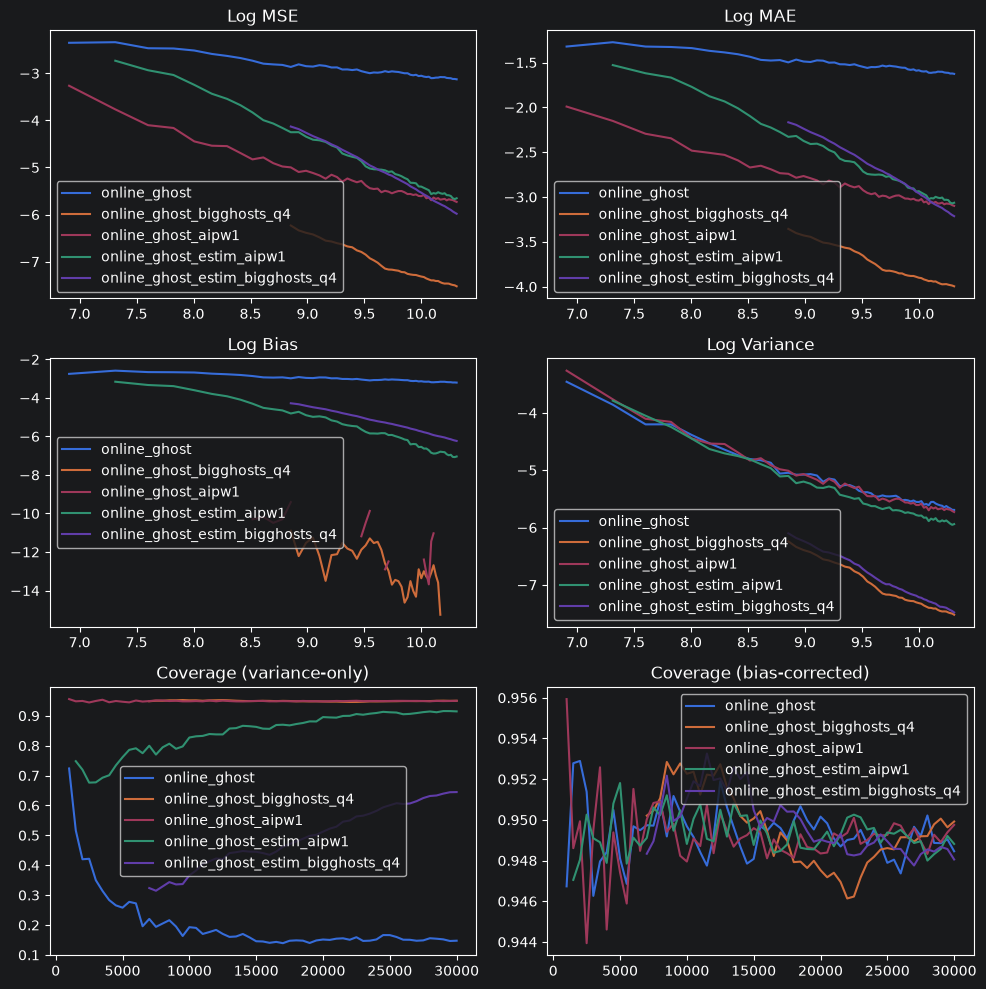

In [46]:
# Checkpoint grids belong to estimator results and need not be identical.
n = [saved_results["estimators"][estimator.name]["checkpoints"] for estimator in ESTIMATORS_TO_RUN]

fig, axes = plt.subplots(3, 2, figsize=(10, 10))

for i in range(len(loss_summaries)):
    axes[0, 0].plot(np.log(n[i]), np.log(estimators_results_dfs[i]['MSE']), label=ESTIMATORS_TO_RUN[i].name)
axes[0, 0].set_title("Log MSE")
axes[0, 0].legend()

for i in range(len(loss_summaries)):
    axes[0, 1].plot(np.log(n[i]), np.log(estimators_results_dfs[i]['MAE']), label=ESTIMATORS_TO_RUN[i].name)
axes[0, 1].set_title("Log MAE")
axes[0, 1].legend()

for i in range(len(loss_summaries)):
    axes[1, 0].plot(np.log(n[i]), np.log(estimators_results_dfs[i]['Bias']), label=ESTIMATORS_TO_RUN[i].name)
axes[1, 0].set_title("Log Bias")
axes[1, 0].legend()

for i in range(len(loss_summaries)):
    axes[1, 1].plot(np.log(n[i]), np.log(estimators_results_dfs[i]['Variance']), label=ESTIMATORS_TO_RUN[i].name)
axes[1, 1].set_title("Log Variance")
axes[1, 1].legend()

for i in range(len(loss_summaries)):
    axes[2, 0].plot(n[i], estimators_results_dfs[i]['Coverage (variance-only)'], label=ESTIMATORS_TO_RUN[i].name)
axes[2, 0].set_title("Coverage (variance-only)")
axes[2, 0].legend()

for i in range(len(loss_summaries)):
    axes[2, 1].plot(n[i], estimators_results_dfs[i]['Coverage (bias-corrected)'], label=ESTIMATORS_TO_RUN[i].name)
axes[2, 1].set_title("Coverage (bias-corrected)")
axes[2, 1].legend()

fig.tight_layout()
plt.show()


In [84]:
def exponent_frame(summary, estimator_name):
    bootstrap = summary["exponents"]["bootstrap"]
    rows = []
    for metric_name, fit in summary["exponents"]["metrics"].items():
        boot = None if bootstrap is None else bootstrap["metrics"][metric_name]
        rows.append({
            "estimator": estimator_name,
            "metric": metric_name,
            "exponent": fit["estimate"],
            "r_squared": fit["r_squared"],
            "n_checkpoints": fit["n_checkpoints"],
            "bootstrap_se": np.nan if boot is None else boot["standard_error"],
            "ci_lower": np.nan if boot is None else boot["confidence_interval"][0],
            "ci_upper": np.nan if boot is None else boot["confidence_interval"][1],
            "bootstrap_valid_fraction": np.nan if boot is None else boot["valid_fraction"],
        })
    return pd.DataFrame(rows)

exponent_results = pd.concat([
    exponent_frame(online_metrics, PRIMARY_ONLINE_ESTIMATOR.name),
    exponent_frame(offline_metrics, PRIMARY_OFFLINE_ESTIMATOR.name),
], ignore_index=True)
exponent_results

,estimator,metric,exponent,r_squared,n_checkpoints,bootstrap_se,ci_lower,ci_upper,bootstrap_valid_fraction
0,online_ghost,mse,0.537538,0.994524,60,0.007686,0.521871,0.552050,1.0
1,online_ghost,mae,0.281307,0.992999,60,0.004336,0.272513,0.289368,1.0
2,online_ghost,squared_bias,0.548342,0.993205,60,0.007982,0.530835,0.562683,1.0
3,online_ghost,variance,0.444231,0.988639,60,0.015995,0.409507,0.473191,1.0
4,offline_econml,mse,0.751301,0.993601,60,0.018271,0.714323,0.786817,1.0
5,offline_econml,mae,0.397793,0.993446,60,0.011046,0.375938,0.418963,1.0
6,offline_econml,squared_bias,0.975044,0.997263,60,0.038932,0.869947,1.020883,1.0
7,offline_econml,variance,0.479714,0.989541,60,0.028703,0.419946,0.532883,1.0


In [85]:
def coverage_frame(summary, estimator_name):
    coverage = summary["coverage"]
    return pd.DataFrame({
        "estimator": estimator_name,
        "checkpoint": summary["checkpoints"].astype(int),
        "variance_only_coverage": coverage["variance_only"],
        "variance_only_mc_se": coverage["variance_only_mc_standard_error"],
        "bias_corrected_coverage": coverage["bias_corrected"],
        "bias_corrected_mc_se": coverage["bias_corrected_mc_standard_error"],
        "variance_only_mean_length": coverage["variance_only_mean_interval_length"],
        "bias_corrected_mean_length": coverage["bias_corrected_mean_interval_length"],
        "variance_only_grid_coverage": coverage["variance_only_simultaneous"],
        "bias_corrected_grid_coverage": coverage["bias_corrected_simultaneous"],
    })

coverage_results = pd.concat([
    coverage_frame(online_metrics, PRIMARY_ONLINE_ESTIMATOR.name),
    coverage_frame(offline_metrics, PRIMARY_OFFLINE_ESTIMATOR.name),
], ignore_index=True)
coverage_results.groupby("estimator").tail(1)

,estimator,checkpoint,variance_only_coverage,variance_only_mc_se,bias_corrected_coverage,bias_corrected_mc_se,variance_only_mean_length,bias_corrected_mean_length,variance_only_grid_coverage,bias_corrected_grid_coverage
59,online_ghost,30000,0.436275,0.017434,0.951686,0.006164,0.426006,0.439117,0.0,0.0
119,offline_econml,30000,0.894882,0.005178,0.949157,0.003017,0.324142,0.334118,0.0,0.0


In [ ]:
# Full data-seed list for fitting a newly added estimator on the same MC draws.
used_seeds = experiment.seeds(R=R)
pd.DataFrame(used_seeds)

# Coverage can differ across estimators; this inventories every saved variant.
experiment.inventory()
